In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import arcadia_pycolor as apc




In [2]:
df = pd.read_csv('../data/Miniprep.csv')

# Replicate columns are read from the header rather than hard-coded, so extra
# rounds added to the CSV (O4, O5, ... H4, ...) are picked up automatically.
def _replicate_cols(prefix):
    cols = [c for c in df.columns if c.startswith(prefix) and c[len(prefix):].isdigit()]
    return sorted(cols, key=lambda c: int(c[len(prefix):]))

O_COLS = _replicate_cols('O')
H_COLS = _replicate_cols('H')


def reps(row, cols):
    """Non-missing replicate values for a row, in column order."""
    return [row[c] for c in cols if pd.notna(row[c])]


# Only plasmids with at least 3 replicates by BOTH methods go into the paper figures, so every
# comparison is between properly replicated samples. The CSV itself is left complete.
MIN_REPS_BOTH = 3
n_o, n_h = df[O_COLS].notna().sum(axis=1), df[H_COLS].notna().sum(axis=1)
keep = (n_o >= MIN_REPS_BOTH) & (n_h >= MIN_REPS_BOTH)
print(f"Dropped {(~keep).sum()} samples with < {MIN_REPS_BOTH} replicates by either method: "
      f"{', '.join(df.loc[~keep, 'Sample'])}")
df = df[keep].reset_index(drop=True)


print(f"Opentrons replicates: {O_COLS}")
print(f"By-hand replicates:   {H_COLS}")
print(f"{len(df)} samples")
df

Dropped 28 samples with < 3 replicates by either method: p10d, p18m, p2d, p33m, p34m, t12m, t13m, t14m, t16m, t18m, t1m, t2m, u17m, u2d, u4d, u4m, u5d, u6d, u9m, P1m, P3d, P4d, P4m, P5d, P61m, P6d, P8d, P9d
Opentrons replicates: ['O1', 'O2', 'O3', 'O4', 'O5', 'O6', 'O7', 'O8']
By-hand replicates:   ['H1', 'H2', 'H3']
5 samples


,Sample,O1,O2,O3,H1,H2,H3,O4,O5,O6,O7,O8
0,c1j,107.0,114.0,72.0,161.0,150.0,159.0,138.5,85.0,64.0,128.0,NaN
1,P1d,174.0,62.5,NaN,59.1,144.0,79.0,89.0,NaN,NaN,NaN,NaN
2,t1d,206.0,40.0,111.0,53.0,53.0,64.0,175.0,NaN,NaN,NaN,NaN
3,u1d,105.0,63.5,37.0,65.0,65.0,69.0,NaN,NaN,NaN,NaN,NaN
4,V37m,62.0,216.0,59.0,33.0,58.0,54.0,84.0,104.0,148.0,58.0,115.0


In [3]:
# Calculate mean and SD for samples with at least 3 replicates
results = []

for idx, row in df.iterrows():
    sample = row['Sample']

    # Opentrons replicates
    o_values = reps(row, O_COLS)
    if len(o_values) >= 3:
        results.append({
            'Sample': sample,
            'Method': 'Opentrons',
            'Mean': np.mean(o_values),
            'SD': np.std(o_values, ddof=1),  # Using sample standard deviation
            'SEM': np.std(o_values, ddof=1) / np.sqrt(len(o_values)),
            'n': len(o_values)
        })

    # By hand replicates
    h_values = reps(row, H_COLS)
    if len(h_values) >= 3:
        results.append({
            'Sample': sample,
            'Method': 'By Hand',
            'Mean': np.mean(h_values),
            'SD': np.std(h_values, ddof=1),  # Using sample standard deviation
            'SEM': np.std(h_values, ddof=1) / np.sqrt(len(h_values)),
            'n': len(h_values)
        })

# Create results dataframe
results_df = pd.DataFrame(results)
results_df

,Sample,Method,Mean,SD,SEM,n
0,c1j,Opentrons,101.214286,28.301733,10.697050,7
1,c1j,By Hand,156.666667,5.859465,3.382964,3
2,P1d,Opentrons,108.500000,58.251609,33.631582,3
3,P1d,By Hand,94.033333,44.401614,25.635284,3
4,t1d,Opentrons,133.000000,73.543638,36.771819,4
5,t1d,By Hand,56.666667,6.350853,3.666667,3
6,u1d,Opentrons,68.500000,34.274626,19.788465,3
7,u1d,By Hand,66.333333,2.309401,1.333333,3
8,V37m,Opentrons,105.750000,54.617501,19.310203,8
9,V37m,By Hand,48.333333,13.428825,7.753136,3


In [4]:
# Find samples that have both methods
samples_with_both = results_df.groupby('Sample').size()
samples_with_both = samples_with_both[samples_with_both == 2].index.tolist()

print(f"Samples with both methods: {samples_with_both}")

# Filter results for only those samples
both_methods_df = results_df[results_df['Sample'].isin(samples_with_both)]
both_methods_df

Samples with both methods: ['P1d', 'V37m', 'c1j', 't1d', 'u1d']


,Sample,Method,Mean,SD,SEM,n
0,c1j,Opentrons,101.214286,28.301733,10.697050,7
1,c1j,By Hand,156.666667,5.859465,3.382964,3
2,P1d,Opentrons,108.500000,58.251609,33.631582,3
3,P1d,By Hand,94.033333,44.401614,25.635284,3
4,t1d,Opentrons,133.000000,73.543638,36.771819,4
5,t1d,By Hand,56.666667,6.350853,3.666667,3
6,u1d,Opentrons,68.500000,34.274626,19.788465,3
7,u1d,By Hand,66.333333,2.309401,1.333333,3
8,V37m,Opentrons,105.750000,54.617501,19.310203,8
9,V37m,By Hand,48.333333,13.428825,7.753136,3


In [5]:
apc.palettes.primary


                        
   aegean    #5088C5
   amber     #F28360
   seaweed   #3B9886
   canary    #F7B846
   aster     #7A77AB
   rose      #F898AE
   vital     #73B5E3
   tangerine #FFB984
   lime      #97CD78
   dragon    #C85152
   oat       #F5E4BE
   wish      #BABEE0

In [6]:
color_opentrons = apc.palettes.primary[4] 
color_byhand = apc.palettes.primary[2] 

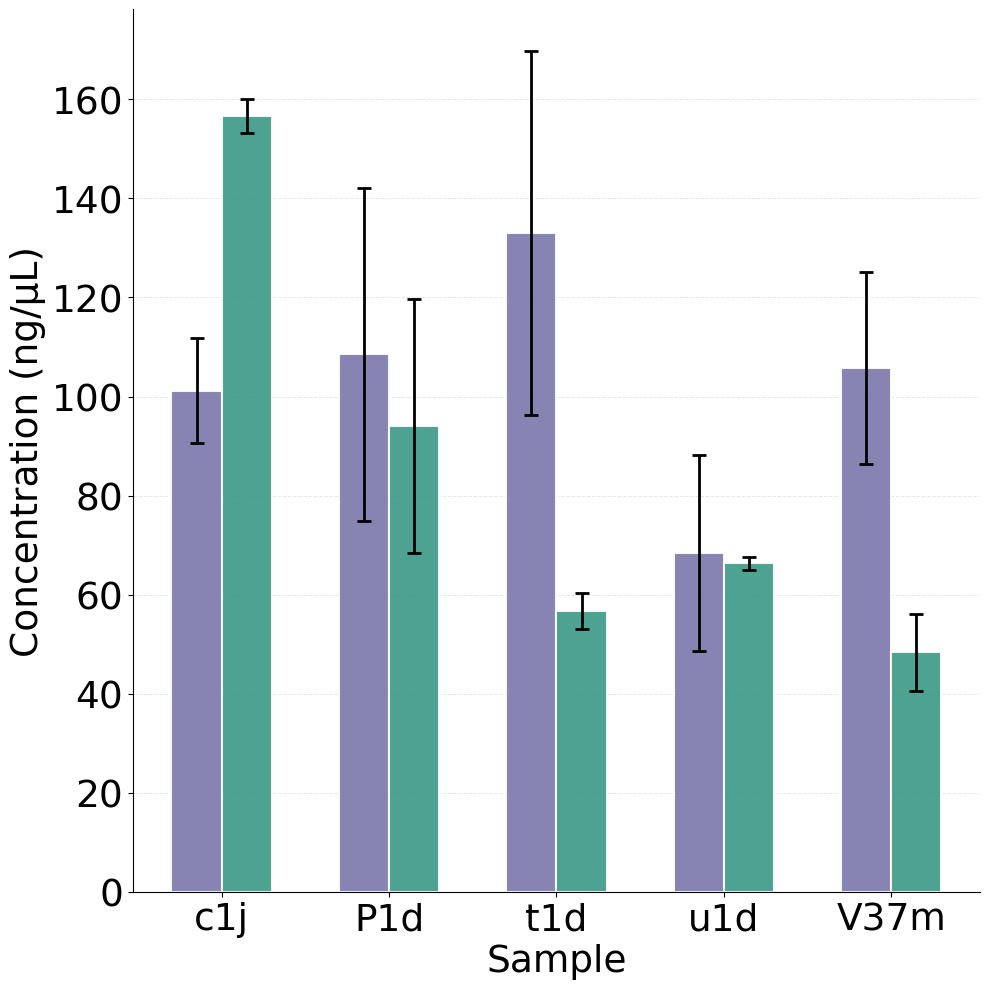

In [7]:
# Prepare data for plotting
samples = both_methods_df['Sample'].unique()
x = np.arange(len(samples))
width = 0.3  # Wider bars = less space between them

# Separate data by method
opentrons_data = both_methods_df[both_methods_df['Method'] == 'Opentrons'].set_index('Sample')
byhand_data = both_methods_df[both_methods_df['Method'] == 'By Hand'].set_index('Sample')

# Create the bar plot with arcadia-pycolor palette
fig, ax = plt.subplots(figsize=(10, 10))

# Use arcadia-pycolor secondary palette
# sky (index 0) and mars (index 6)
     

bars1 = ax.bar(x - width/2, opentrons_data.loc[samples, 'Mean'], width, 
               yerr=opentrons_data.loc[samples, 'SEM'],
               label='Opentrons', capsize=5, alpha=0.9,
               color=color_opentrons, edgecolor='white', linewidth=1.5,
               error_kw={'linewidth': 2, 'elinewidth': 2, 'capthick': 2})

bars2 = ax.bar(x + width/2, byhand_data.loc[samples, 'Mean'], width,
               yerr=byhand_data.loc[samples, 'SEM'],
               label='By Hand', capsize=5, alpha=0.9,
               color=color_byhand, edgecolor='white', linewidth=1.5,
               error_kw={'linewidth': 2, 'elinewidth': 2, 'capthick': 2})

# Customize the plot
ax.set_xlabel('Sample', fontsize=27)
ax.set_ylabel('Concentration (ng/μL)', fontsize=27)
#ax.set_title('Miniprep Comparison: Opentrons vs By Hand', 
      #       fontsize=19, pad=20)
ax.set_xticks(x)
ax.set_xticklabels(samples, fontsize=27)
ax.tick_params(axis='y', labelsize=27)

# Add subtle grid
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax.set_axisbelow(True)

# Set y-axis to start at 0 for better comparison
ax.set_ylim(bottom=0)

# Enhanced legend - positioned outside to the right
#ax.legend(fontsize=15, frameon=False,
        #  loc='center left', bbox_to_anchor=(1, 0.5))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../plots/TriplicateSamples.svg', dpi=1000)
plt.show()

In [8]:
# Calculate mean yield for all samples (including those with incomplete triplicates)
all_results = []

for idx, row in df.iterrows():
    sample = row['Sample']

    # Opentrons replicates
    o_values = reps(row, O_COLS)
    if len(o_values) > 0:  # Any data points
        all_results.append({
            'Sample': sample,
            'Method': 'Opentrons',
            'Mean': np.mean(o_values),
            'SD': np.std(o_values, ddof=1) if len(o_values) > 1 else 0,
            'SEM': np.std(o_values, ddof=1) / np.sqrt(len(o_values)) if len(o_values) > 1 else 0,
            'n': len(o_values)
        })

    # By hand replicates
    h_values = reps(row, H_COLS)
    if len(h_values) > 0:  # Any data points
        all_results.append({
            'Sample': sample,
            'Method': 'By Hand',
            'Mean': np.mean(h_values),
            'SD': np.std(h_values, ddof=1) if len(h_values) > 1 else 0,
            'SEM': np.std(h_values, ddof=1) / np.sqrt(len(h_values)) if len(h_values) > 1 else 0,
            'n': len(h_values)
        })

# Create results dataframe
all_results_df = pd.DataFrame(all_results)

# Find samples with both methods
all_samples_both = all_results_df.groupby('Sample').size()
all_samples_both = all_samples_both[all_samples_both == 2].index.tolist()

print(f"Total samples with both methods: {len(all_samples_both)}")
print(f"Samples: {sorted(all_samples_both)}")

# Samples measured by only one method (e.g. the Opentrons-only P* rows)
opentrons_only = sorted(set(all_results_df['Sample']) - set(all_samples_both))
print(f"Single-method samples (excluded from paired comparisons): {opentrons_only}")

# Filter for samples with both methods
both_methods_all_df = all_results_df[all_results_df['Sample'].isin(all_samples_both)]
both_methods_all_df

Total samples with both methods: 5
Samples: ['P1d', 'V37m', 'c1j', 't1d', 'u1d']
Single-method samples (excluded from paired comparisons): []


,Sample,Method,Mean,SD,SEM,n
0,c1j,Opentrons,101.214286,28.301733,10.697050,7
1,c1j,By Hand,156.666667,5.859465,3.382964,3
2,P1d,Opentrons,108.500000,58.251609,33.631582,3
3,P1d,By Hand,94.033333,44.401614,25.635284,3
4,t1d,Opentrons,133.000000,73.543638,36.771819,4
5,t1d,By Hand,56.666667,6.350853,3.666667,3
6,u1d,Opentrons,68.500000,34.274626,19.788465,3
7,u1d,By Hand,66.333333,2.309401,1.333333,3
8,V37m,Opentrons,105.750000,54.617501,19.310203,8
9,V37m,By Hand,48.333333,13.428825,7.753136,3


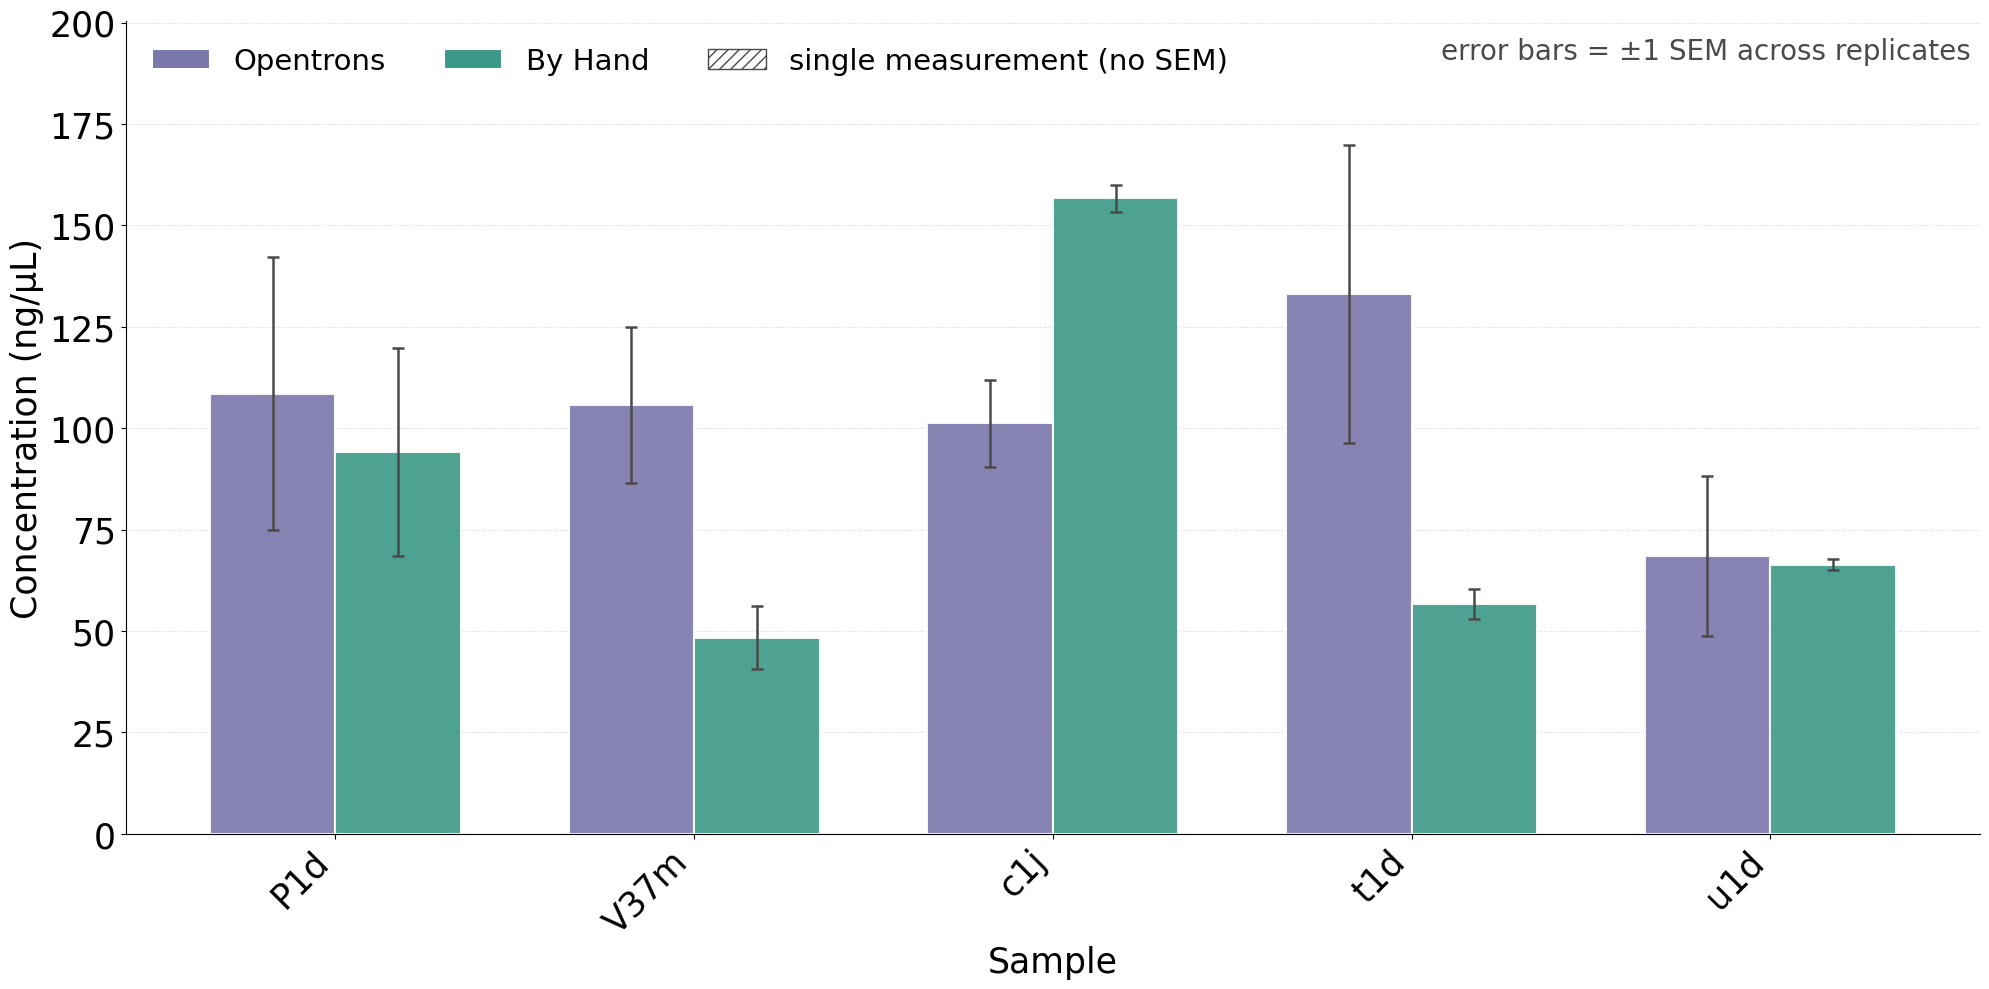

In [9]:
# Prepare data for plotting all samples
samples_all = sorted(both_methods_all_df['Sample'].unique())
x_all = np.arange(len(samples_all))
width_all = 0.35

# Separate data by method
opentrons_all = both_methods_all_df[both_methods_all_df['Method'] == 'Opentrons'].set_index('Sample')
byhand_all = both_methods_all_df[both_methods_all_df['Method'] == 'By Hand'].set_index('Sample')


def err_and_hatch(frame):
    """SEM error bars, suppressed (NaN) where there is only one measurement.

    A single measurement has no spread to show - drawing a zero-length bar would
    read as 'perfectly reproducible', so those bars are hatched instead.
    """
    n = frame.loc[samples_all, 'n'].values
    sd = frame.loc[samples_all, 'SEM'].values
    yerr = np.where(n > 1, sd, np.nan)
    hatches = ['' if k > 1 else '///' for k in n]
    return yerr, hatches


o_err, o_hatch = err_and_hatch(opentrons_all)
h_err, h_hatch = err_and_hatch(byhand_all)

# Create the bar plot
fig, ax = plt.subplots(figsize=(20, 10))

bars1 = ax.bar(x_all - width_all/2, opentrons_all.loc[samples_all, 'Mean'], width_all,
               yerr=o_err, capsize=4,
               label='Opentrons', alpha=0.9,
               color=color_opentrons, edgecolor='white', linewidth=1.5,
               error_kw={'linewidth': 1.8, 'elinewidth': 1.8, 'capthick': 1.8,
                         'ecolor': '#4A4A4A'})

bars2 = ax.bar(x_all + width_all/2, byhand_all.loc[samples_all, 'Mean'], width_all,
               yerr=h_err, capsize=4,
               label='By Hand', alpha=0.9,
               color=color_byhand, edgecolor='white', linewidth=1.5,
               error_kw={'linewidth': 1.8, 'elinewidth': 1.8, 'capthick': 1.8,
                         'ecolor': '#4A4A4A'})

# Hatch the bars that are a single measurement rather than a replicate mean
for bar, hatch in zip(bars1, o_hatch):
    bar.set_hatch(hatch)
for bar, hatch in zip(bars2, h_hatch):
    bar.set_hatch(hatch)

# Customize the plot
ax.set_xlabel('Sample', fontsize=25)
ax.set_ylabel('Concentration (ng/μL)', fontsize=25)
#ax.set_title('Miniprep Yield Comparison: All Samples',
#             fontsize=19, pad=20)
ax.set_xticks(x_all)
ax.set_xticklabels(samples_all, fontsize=25, rotation=45, ha='right')
ax.tick_params(axis='y', labelsize=25)

# Add subtle grid
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax.set_axisbelow(True)

# Headroom for the legend above the tallest error bar
top = np.nanmax([
    (opentrons_all.loc[samples_all, 'Mean'].values + np.nan_to_num(o_err)).max(),
    (byhand_all.loc[samples_all, 'Mean'].values + np.nan_to_num(h_err)).max(),
])
ax.set_ylim(0, top * 1.18)

# Apply arcadia styling before creating legend
#apc.mpl.style_plot(monospaced_axes = "both")

# Legend: methods plus an explanation of the hatched (single-measurement) bars
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=color_opentrons, edgecolor='white', linewidth=1.5, label='Opentrons'),
    Patch(facecolor=color_byhand, edgecolor='white', linewidth=1.5, label='By Hand'),
    Patch(facecolor='white', edgecolor='#4A4A4A', hatch='///',
          label='single measurement (no SEM)'),
]
ax.legend(handles=legend_elements, fontsize=21, frameon=False, loc='upper left', ncol=3)
ax.text(0.995, 0.98, 'error bars = ±1 SEM across replicates',
        transform=ax.transAxes, ha='right', va='top', fontsize=20, color='#4A4A4A')

# remove right and top borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../plots/AllSamples.svg', dpi=1000)
plt.show()


In [10]:
# Calculate mean and SD for each replicate column across all samples
replicate_stats = []

for col in O_COLS + H_COLS:
    values = df[col].dropna()
    if len(values) > 0:
        replicate_stats.append({
            'Replicate': col,
            'Method': 'Opentrons' if col.startswith('O') else 'By Hand',
            'Mean': np.mean(values),
            'SD': np.std(values, ddof=1) if len(values) > 1 else 0,
            'SEM': np.std(values, ddof=1) / np.sqrt(len(values)) if len(values) > 1 else 0,
            'Count': len(values)
        })

replicate_df = pd.DataFrame(replicate_stats)

# Rounds are repeat cultures, not a fixed design: later rounds only re-ran a subset of plasmids,
# which is why n differs between rounds (reviewers R1, R7). List exactly what each round holds.
round_members = {col: sorted(df.loc[df[col].notna(), 'Sample']) for col in O_COLS + H_COLS}
for col, members in round_members.items():
    print(f"{col} (n={len(members)}): {', '.join(members)}")

replicate_df

O1 (n=5): P1d, V37m, c1j, t1d, u1d
O2 (n=5): P1d, V37m, c1j, t1d, u1d
O3 (n=4): V37m, c1j, t1d, u1d
O4 (n=4): P1d, V37m, c1j, t1d
O5 (n=2): V37m, c1j
O6 (n=2): V37m, c1j
O7 (n=2): V37m, c1j
O8 (n=1): V37m
H1 (n=5): P1d, V37m, c1j, t1d, u1d
H2 (n=5): P1d, V37m, c1j, t1d, u1d
H3 (n=5): P1d, V37m, c1j, t1d, u1d


,Replicate,Method,Mean,SD,SEM,Count
0,O1,Opentrons,130.800,58.066341,25.968057,5
1,O2,Opentrons,99.200,70.688224,31.612735,5
2,O3,Opentrons,69.750,31.063108,15.531554,4
3,O4,Opentrons,121.625,43.257706,21.628853,4
4,O5,Opentrons,94.500,13.435029,9.500000,2
5,O6,Opentrons,106.000,59.396970,42.000000,2
6,O7,Opentrons,93.000,49.497475,35.000000,2
7,O8,Opentrons,115.000,0.000000,0.000000,1
8,H1,By Hand,74.220,49.984418,22.353711,5
9,H2,By Hand,94.000,48.615841,21.741665,5


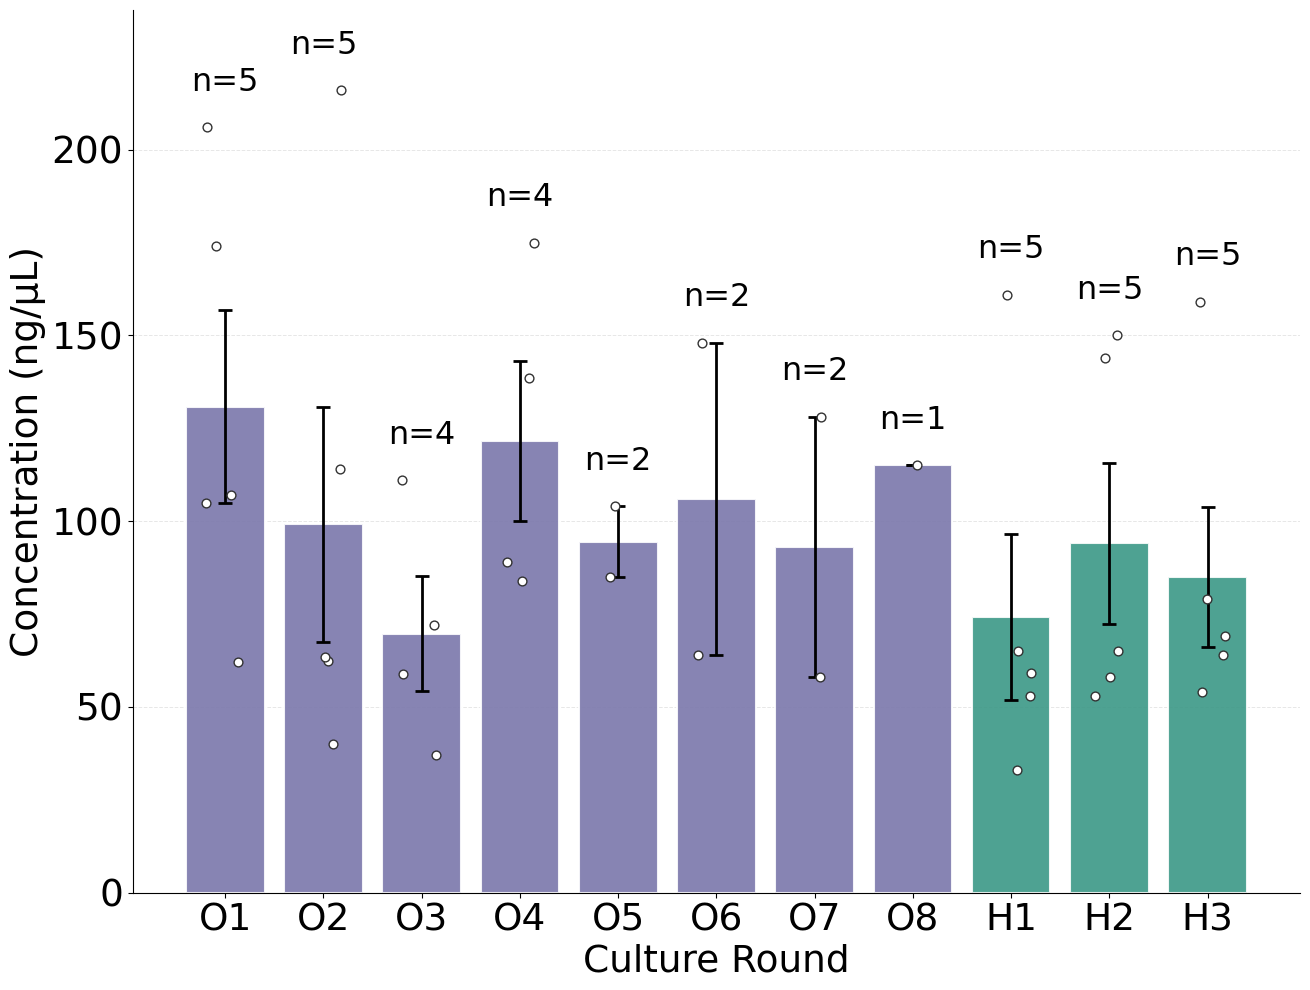

Opentrons rounds ['O1', 'O2', 'O3', 'O4']: Kruskal-Wallis H = 3.40, p = 0.333
By Hand rounds ['H1', 'H2', 'H3']: Kruskal-Wallis H = 0.86, p = 0.650


In [11]:
from scipy import stats

# Create bar plot for each replicate round, with every sample shown as a point
fig, ax = plt.subplots(figsize=(max(10, 1.2 * len(replicate_df)), 10))

# Prepare x positions
replicates = replicate_df['Replicate'].tolist()
x_rep = np.arange(len(replicates))
colors = [color_opentrons if method == 'Opentrons' else color_byhand
          for method in replicate_df['Method']]

# Create bars
bars = ax.bar(x_rep, replicate_df['Mean'],
              yerr=replicate_df['SEM'],
              color=colors, alpha=0.9,
              edgecolor='white', linewidth=1.5,
              capsize=5,
              error_kw={'linewidth': 2, 'elinewidth': 2, 'capthick': 2})

# Overlay the individual sample yields so the spread and n are visible directly
jitter = np.random.default_rng(0)
for i, col in enumerate(replicates):
    values = df[col].dropna().values
    ax.scatter(i + jitter.uniform(-0.2, 0.2, len(values)), values, s=40, color='white',
               edgecolor='#333333', linewidth=1, zorder=3)

# Customize the plot
ax.set_xlabel('Culture Round', fontsize=27)
ax.set_ylabel('Concentration (ng/μL)', fontsize=27)
ax.set_xticks(x_rep)
ax.set_xticklabels(replicates, fontsize=27)
ax.tick_params(axis='y', labelsize=27)

# Add count annotations above the highest point or error bar of each round
for i, col in enumerate(replicates):
    top = max(df[col].max(), replicate_df['Mean'].iloc[i] + replicate_df['SEM'].iloc[i])
    ax.text(i, top + 8, f'n={replicate_df["Count"].iloc[i]}',
            ha='center', va='bottom', fontsize=23, color='black')

# Add subtle grid
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax.set_axisbelow(True)

# Leave headroom for the n labels above the tallest round
ax.set_ylim(0, df[replicates].max().max() * 1.1)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../plots/RoundComparison.svg', dpi=1000)
plt.show()

# Do rounds differ? Kruskal-Wallis within each method, over rounds with at least 3 samples
for method, cols in [('Opentrons', O_COLS), ('By Hand', H_COLS)]:
    groups = [df[c].dropna().values for c in cols if df[c].notna().sum() >= 3]
    used = [c for c in cols if df[c].notna().sum() >= 3]
    kw = stats.kruskal(*groups)
    print(f"{method} rounds {used}: Kruskal-Wallis H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}")

In [12]:
from scipy import stats

# Define yield thresholds
thresholds = [25, 50, 75, 100, 150]


def wilson_ci(k, n, z=1.96):
    # 95% Wilson score interval for a proportion, returned in %
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (centre - half), 100 * (centre + half)


# Success is scored per prep (every replicate is one attempt), since with only a handful of
# plasmids a rate over sample means moves in very coarse steps
prep_yields = {'Opentrons': df[O_COLS].stack().values, 'By Hand': df[H_COLS].stack().values}

# Calculate success rates for each method and threshold
success_data = []

for method in ['Opentrons', 'By Hand']:
    yields = prep_yields[method]

    for threshold in thresholds:
        count_above = int((yields >= threshold).sum())
        total_count = len(yields)
        ci_low, ci_high = wilson_ci(count_above, total_count)

        success_data.append({
            'Method': method,
            'Threshold': f'≥{threshold}',
            'Threshold_Value': threshold,
            'Success_Rate': 100 * count_above / total_count,
            'CI_low': ci_low,
            'CI_high': ci_high,
            'Count': count_above,
            'Total': total_count
        })

success_df = pd.DataFrame(success_data)

# Fisher's exact test per threshold on the 2x2 table of pass/fail by method. Preps from the same
# plasmid are not fully independent, so treat these p values as descriptive.
fisher = []
for threshold in thresholds:
    table = [[(prep_yields[m] >= threshold).sum(), (prep_yields[m] < threshold).sum()]
             for m in ['Opentrons', 'By Hand']]
    fisher.append({'Threshold': f'≥{threshold}', 'Fisher p': stats.fisher_exact(table).pvalue})
fisher_df = pd.DataFrame(fisher)

print(fisher_df.to_string(index=False))
success_df

Threshold  Fisher p
      ≥25  1.000000
      ≥50  1.000000
      ≥75  0.101780
     ≥100  0.187368
     ≥150  1.000000


,Method,Threshold,Threshold_Value,Success_Rate,CI_low,CI_high,Count,Total
0,Opentrons,≥25,25,100.000000,86.680351,100.000000,25,25
1,Opentrons,≥50,50,92.000000,75.033488,97.778007,23,25
2,Opentrons,≥75,75,64.000000,44.518155,79.752344,16,25
3,Opentrons,≥100,100,52.000000,33.498218,69.968996,13,25
4,Opentrons,≥150,150,16.000000,6.403348,34.654014,4,25
5,By Hand,≥25,25,100.000000,79.611073,100.000000,15,15
6,By Hand,≥50,50,93.333333,70.182922,98.813341,14,15
7,By Hand,≥75,75,33.333333,15.176101,58.286875,5,15
8,By Hand,≥100,100,26.666667,10.897276,51.950890,4,15
9,By Hand,≥150,150,20.000000,7.047421,45.185935,3,15


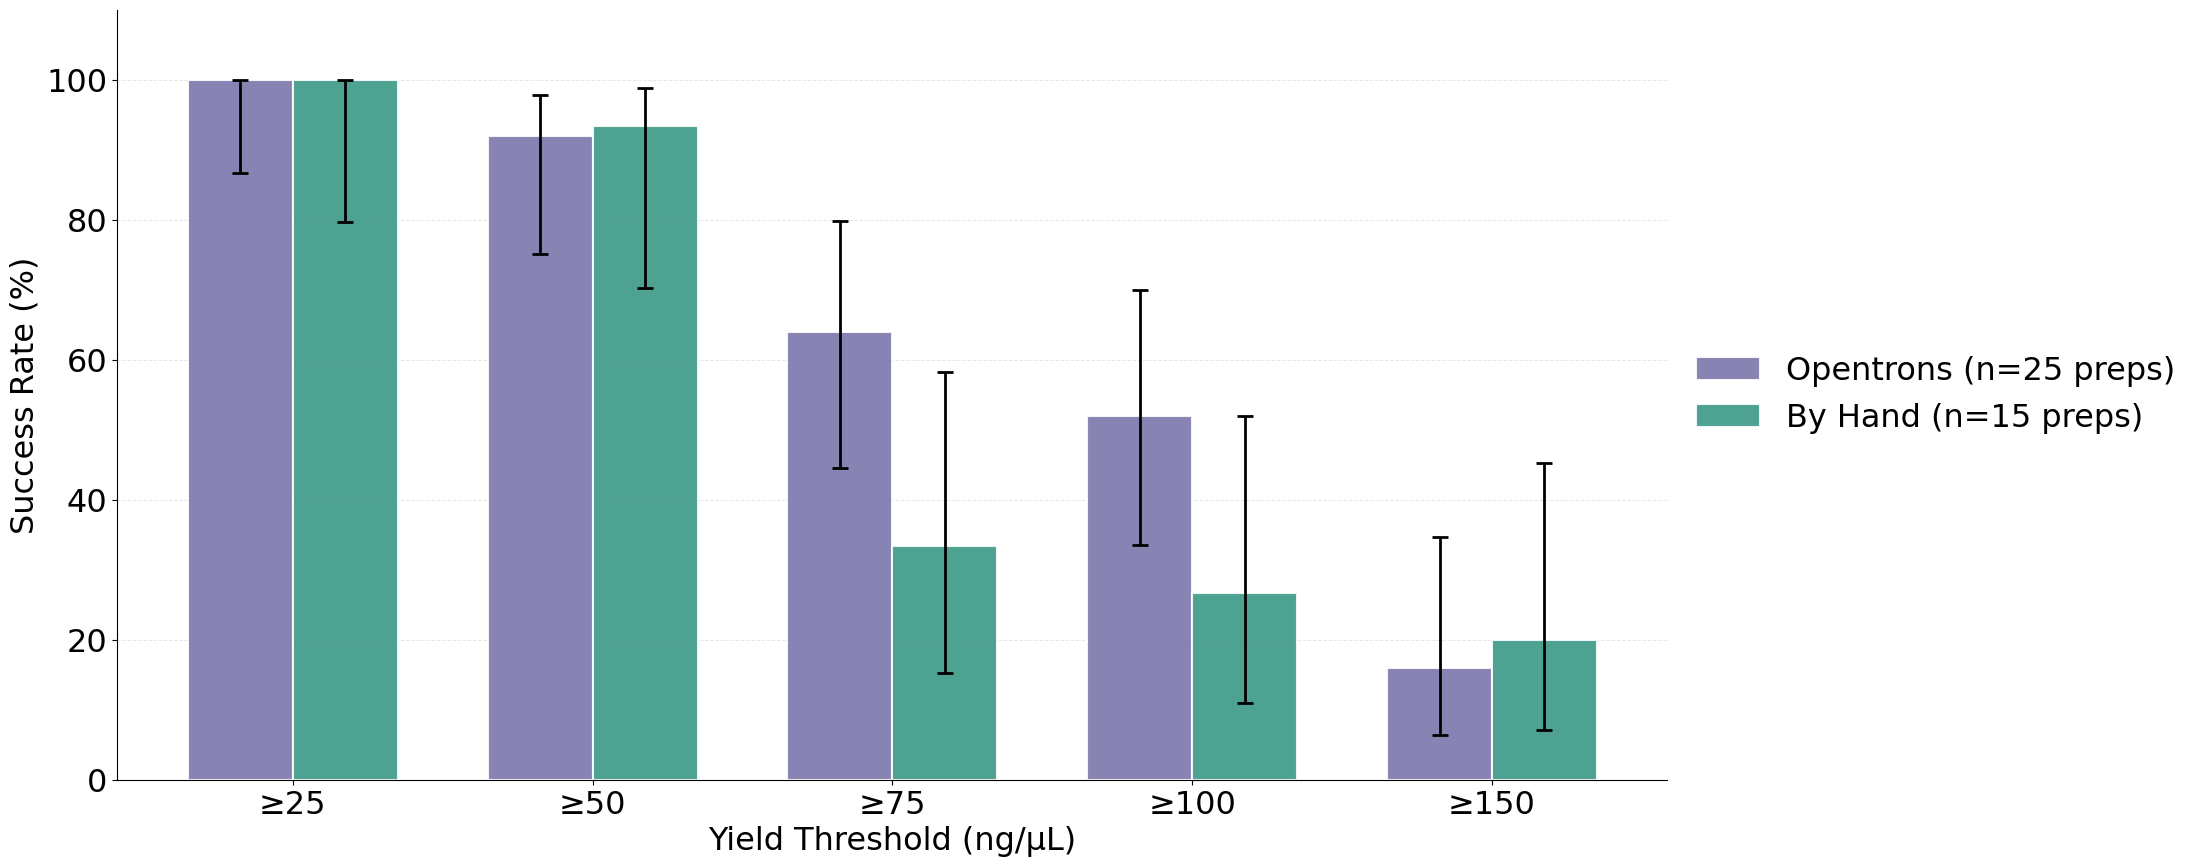

For the legend (Fisher's exact test, n = individual preps from 5 plasmids):
≥25: p = 1.000; ≥50: p = 1.000; ≥75: p = 0.102; ≥100: p = 0.187; ≥150: p = 1.000


In [13]:
# Create success rate plot with 95% Wilson confidence intervals (n = preps).
# Drawn by a function so the combined figure at the end of the notebook reuses it.
def plot_success_rate(ax):
    # Prepare data for grouped bar plot
    opentrons_success = success_df[success_df['Method'] == 'Opentrons']
    byhand_success = success_df[success_df['Method'] == 'By Hand']

    x_pos = np.arange(len(thresholds))
    width = 0.35
    error_style = {'linewidth': 2, 'elinewidth': 2, 'capthick': 2}

    # Create bars; error bars are the asymmetric 95% CI around each success rate
    for offset, data, color, label in [(-width / 2, opentrons_success, color_opentrons, 'Opentrons'),
                                       (width / 2, byhand_success, color_byhand, 'By Hand')]:
        yerr = [data['Success_Rate'] - data['CI_low'], data['CI_high'] - data['Success_Rate']]
        ax.bar(x_pos + offset, data['Success_Rate'], width, yerr=yerr,
               label=f"{label} (n={data['Total'].iloc[0]} preps)", alpha=0.9,
               color=color, edgecolor='white', linewidth=1.5, capsize=6, error_kw=error_style)

    # Customize the plot
    ax.set_xlabel('Yield Threshold (ng/μL)', fontsize=23)
    ax.set_ylabel('Success Rate (%)', fontsize=23)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([f'≥{t}' for t in thresholds], fontsize=23)
    ax.tick_params(axis='y', labelsize=23)

    # Add subtle grid
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
    ax.set_axisbelow(True)

    # Set y-axis limits
    ax.set_ylim(0, 110)

    # Enhanced legend
    ax.legend(fontsize=23, frameon=False,
              loc='center left', bbox_to_anchor=(1, 0.5))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


fig, ax = plt.subplots(figsize=(20, 10))
plot_success_rate(ax)
plt.savefig('../plots/SuccessRate.svg', dpi=1000, bbox_inches='tight')
plt.show()

print(f"For the legend (Fisher's exact test, n = individual preps from {len(df)} plasmids):")
print('; '.join(f"{r['Threshold']}: p = {r['Fisher p']:.3f}" for _, r in fisher_df.iterrows()))

In [14]:
# Prepare data for heatmap - create a pivot table with means for each sample and method
heatmap_data = both_methods_all_df.pivot(index='Method', columns='Sample', values='Mean')

# Reorder index to have Opentrons first, then By Hand
heatmap_data = heatmap_data.reindex(['Opentrons', 'By Hand'])

# Sort columns by sample name for better organization
heatmap_data = heatmap_data[sorted(heatmap_data.columns)]

heatmap_data


Sample,P1d,V37m,c1j,t1d,u1d
Method,,,,,
Opentrons,108.500000,105.750000,101.214286,133.000000,68.500000
By Hand,94.033333,48.333333,156.666667,56.666667,66.333333


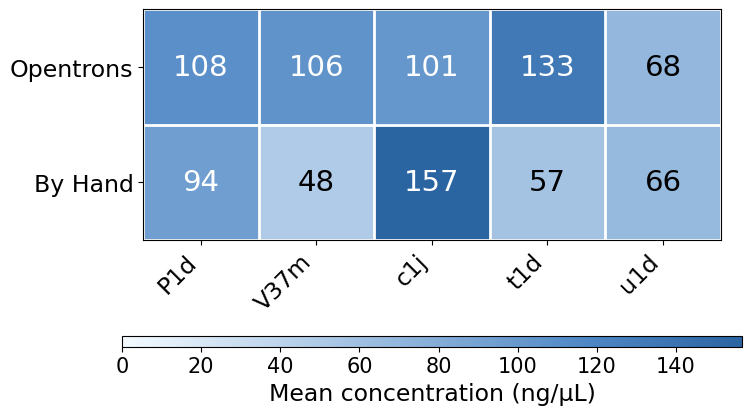

In [15]:
# Heatmap of mean yield per sample and method. Darker = higher concentration, and every cell
# carries its value so the figure doubles as a table (reviewers R4, R5).
fig, ax = plt.subplots(figsize=(max(8, 1.6 * heatmap_data.shape[1]), 5))

vmax = np.nanmax(heatmap_data.values)
im = ax.imshow(heatmap_data.values, cmap=apc.gradients.blues.to_mpl_cmap().reversed(),
               aspect='equal', vmin=0, vmax=vmax)

# Print each value; white text on the darker cells
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        v = heatmap_data.values[i, j]
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=21,
                color='white' if v / vmax > 0.55 else 'black')

# Set ticks and labels
ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_xticklabels(heatmap_data.columns, fontsize=17, rotation=45, ha='right')
ax.set_yticklabels(heatmap_data.index, fontsize=17)

# Add white grid lines like seaborn
ax.set_xticks(np.arange(len(heatmap_data.columns)+1)-0.5, minor=True)
ax.set_yticks(np.arange(len(heatmap_data.index)+1)-0.5, minor=True)
ax.grid(which="minor", color="white", linestyle='-', linewidth=2)
ax.tick_params(which="minor", size=0)

# Add horizontal colorbar underneath
cbar = plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.25, aspect=60)
cbar.set_label('Mean concentration (ng/μL)', fontsize=17)
cbar.ax.tick_params(labelsize=15)

plt.savefig('../plots/Heatmap.svg', dpi=1000, bbox_inches='tight')
plt.show()

In [16]:
from scipy import stats

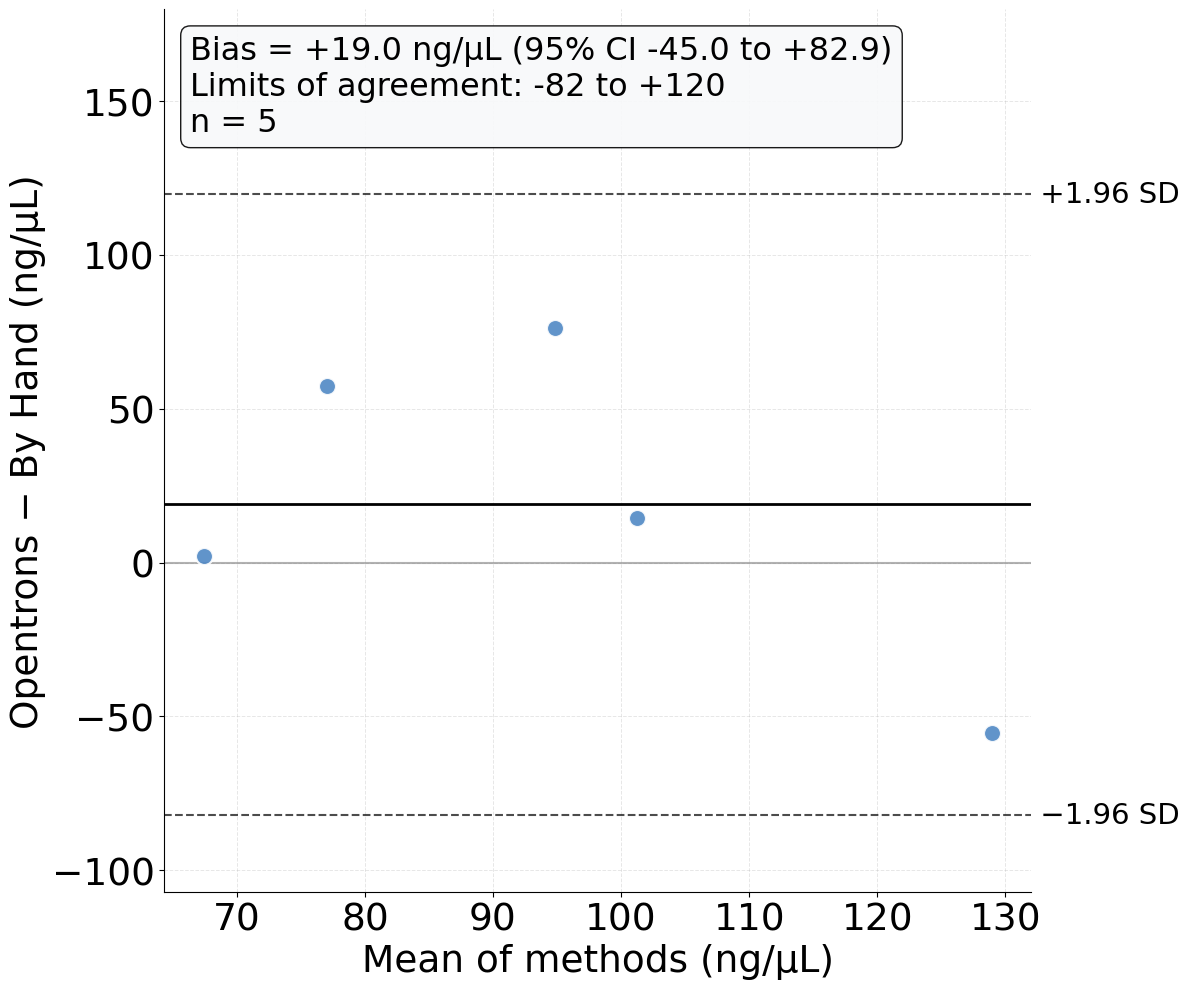

Bias +19.0 ng/μL, limits of agreement -82.0 to 119.9
Paired t-test p = 0.456; Wilcoxon p = 0.312
Geometric mean ratio Opentrons/By Hand = 1.32 (95% CI 0.67-2.58)
Opentrons higher in 4/5 samples


In [17]:
# Bland-Altman agreement plot (replaces the Opentrons vs by-hand correlation scatter).
# The scatter had R² = 0.009, i.e. sample-level yields do not correlate between methods, so the
# question is agreement: the paired difference against the pair mean, with the mean bias and
# 95% limits of agreement (reviewers R1, R7).
paired = both_methods_all_df.pivot(index='Sample', columns='Method', values='Mean').dropna()
o_means, h_means = paired['Opentrons'].values, paired['By Hand'].values

pair_mean = (o_means + h_means) / 2
diff = o_means - h_means
n_pairs = len(diff)
bias = diff.mean()
sd_diff = diff.std(ddof=1)
loa_low, loa_high = bias - 1.96 * sd_diff, bias + 1.96 * sd_diff
bias_half_ci = stats.t.ppf(0.975, n_pairs - 1) * sd_diff / np.sqrt(n_pairs)
wilcoxon_p = stats.wilcoxon(o_means, h_means).pvalue
ttest_p = stats.ttest_rel(o_means, h_means).pvalue
# Yield is multiplicative, so also report the geometric mean ratio
log_ratio = np.log(o_means / h_means)
geo_ratio = np.exp(log_ratio.mean())
geo_ratio_ci = np.exp(log_ratio.mean() + np.array([-1, 1]) * stats.t.ppf(0.975, n_pairs - 1)
                      * log_ratio.std(ddof=1) / np.sqrt(n_pairs))

fig, ax = plt.subplots(figsize=(12, 10))
ax.scatter(pair_mean, diff, s=150, alpha=0.9,
           color=apc.palettes.primary[0], edgecolor='white', linewidth=1.5, zorder=3)
ax.axhline(0, color='grey', linewidth=1.5, alpha=0.6)
ax.axhline(bias, color='black', linewidth=2, label=f'Mean bias ({bias:+.1f})')
for loa in (loa_low, loa_high):
    ax.axhline(loa, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax.text(ax.get_xlim()[1], loa_high, ' +1.96 SD', va='center', ha='left', fontsize=21)
ax.text(ax.get_xlim()[1], loa_low, ' −1.96 SD', va='center', ha='left', fontsize=21)

# Name the samples that fall outside the limits of agreement
for s, x, y in zip(paired.index, pair_mean, diff):
    if y > loa_high or y < loa_low:
        ax.annotate(s, (x, y), xytext=(8, 0), textcoords='offset points', fontsize=21, va='center')

# Wilcoxon p value: statistics go in the figure legend (reviewer request); values are printed by the analysis cells (below)
textstr = (f'Bias = {bias:+.1f} ng/μL (95% CI {bias - bias_half_ci:+.1f} to {bias + bias_half_ci:+.1f})\n'
           f'Limits of agreement: {loa_low:.0f} to {loa_high:+.0f}\n'
           f'n = {n_pairs}')
props = dict(boxstyle='round', facecolor='#f8f9fa', alpha=0.9)
ax.text(0.03, 0.97, textstr, transform=ax.transAxes, fontsize=23,
        verticalalignment='top', bbox=props)

ax.set_xlabel('Mean of methods (ng/μL)', fontsize=27)
ax.set_ylabel('Opentrons − By Hand (ng/μL)', fontsize=27)
ax.tick_params(axis='both', labelsize=27)
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax.grid(axis='x', alpha=0.3, linestyle='--', linewidth=0.7)
ax.set_axisbelow(True)
ax.set_ylim(min(diff.min(), loa_low) - 25, max(diff.max(), loa_high) + 60)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../plots/BlandAltman.svg', dpi=1000, bbox_inches='tight')
plt.show()

print(f"Bias {bias:+.1f} ng/μL, limits of agreement {loa_low:.1f} to {loa_high:.1f}")
print(f"Paired t-test p = {ttest_p:.3f}; Wilcoxon p = {wilcoxon_p:.3f}")
print(f"Geometric mean ratio Opentrons/By Hand = {geo_ratio:.2f} (95% CI {geo_ratio_ci[0]:.2f}-{geo_ratio_ci[1]:.2f})")
print(f"Opentrons higher in {(diff > 0).sum()}/{n_pairs} samples")

In [18]:
# Calculate CV (coefficient of variation) for each sample and method
cv_results = []

for idx, row in df.iterrows():
    sample = row['Sample']

    # Opentrons replicates
    o_values = reps(row, O_COLS)
    if len(o_values) > 1:  # Need at least 2 points to calculate CV
        mean = np.mean(o_values)
        sd = np.std(o_values, ddof=1)
        cv = (sd / mean) * 100 if mean > 0 else np.nan
        cv_results.append({
            'Sample': sample,
            'Method': 'Opentrons',
            'CV': cv,
            'Mean': mean,
            'SD': sd,
            'n': len(o_values)
        })

    # By hand replicates
    h_values = reps(row, H_COLS)
    if len(h_values) > 1:  # Need at least 2 points to calculate CV
        mean = np.mean(h_values)
        sd = np.std(h_values, ddof=1)
        cv = (sd / mean) * 100 if mean > 0 else np.nan
        cv_results.append({
            'Sample': sample,
            'Method': 'By Hand',
            'CV': cv,
            'Mean': mean,
            'SD': sd,
            'n': len(h_values)
        })

cv_df = pd.DataFrame(cv_results)

# Filter for samples with both methods
cv_samples_both = cv_df.groupby('Sample').size()
cv_samples_both = cv_samples_both[cv_samples_both == 2].index.tolist()
cv_both_methods = cv_df[cv_df['Sample'].isin(cv_samples_both)]

cv_both_methods

,Sample,Method,CV,Mean,SD,n
0,c1j,Opentrons,27.962192,101.214286,28.301733,7
1,c1j,By Hand,3.740084,156.666667,5.859465,3
2,P1d,Opentrons,53.688119,108.500000,58.251609,3
3,P1d,By Hand,47.219015,94.033333,44.401614,3
4,t1d,Opentrons,55.295968,133.000000,73.543638,4
5,t1d,By Hand,11.207388,56.666667,6.350853,3
6,u1d,Opentrons,50.035951,68.500000,34.274626,3
7,u1d,By Hand,3.481509,66.333333,2.309401,3
8,V37m,Opentrons,51.647755,105.750000,54.617501,8
9,V37m,By Hand,27.783775,48.333333,13.428825,3


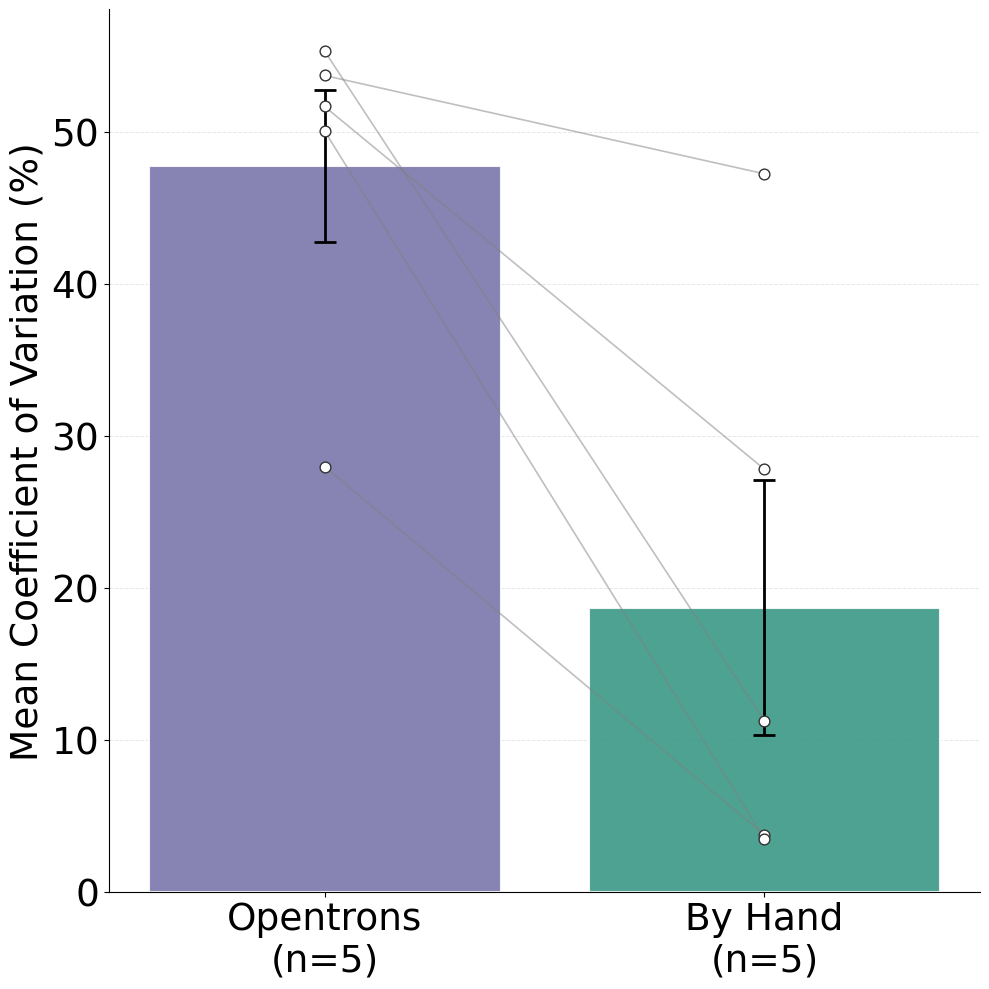


Aggregate CV Statistics (5 samples: P1d, V37m, c1j, t1d, u1d):
Opentrons: 47.73% ± 5.02% (SEM)
By Hand: 18.69% ± 8.39% (SEM)
Wilcoxon signed-rank (paired by sample): p = 0.062


In [19]:
# Create aggregate CV comparison plot.
# CV = SD / mean x 100 per sample per method (samples with >= 2 replicates by both methods),
# then averaged across samples; error bars are the SEM of the per-sample CVs.
fig, ax = plt.subplots(figsize=(10, 10))

# Calculate aggregate statistics for each method
methods = ['Opentrons', 'By Hand']
cv_paired = cv_both_methods.pivot(index='Sample', columns='Method', values='CV')[methods]
aggregate_cv = cv_paired.mean().values
aggregate_sd = cv_paired.std(ddof=1).values / np.sqrt(len(cv_paired))  # SEM of the mean CV

# Create bar plot
x_pos = np.arange(len(methods))
bars = ax.bar(x_pos, aggregate_cv,
              yerr=aggregate_sd,
              color=[color_opentrons, color_byhand],
              alpha=0.9,
              edgecolor='white',
              linewidth=1.5,
              capsize=8,
              error_kw={'linewidth': 2, 'elinewidth': 2, 'capthick': 2})

# Per-sample CVs, joined by sample so the pairing is visible
for _, row in cv_paired.iterrows():
    ax.plot(x_pos, row.values, color='grey', alpha=0.5, linewidth=1.2, zorder=3)
ax.scatter(np.repeat(x_pos[None, :], len(cv_paired), axis=0).ravel(), cv_paired.values.ravel(),
           s=60, color='white', edgecolor='#333333', linewidth=1, zorder=4)

cv_wilcoxon_p = stats.wilcoxon(cv_paired['Opentrons'], cv_paired['By Hand']).pvalue

# Customize the plot
ax.set_ylabel('Mean Coefficient of Variation (%)', fontsize=27)
ax.set_xticks(x_pos)
ax.set_xticklabels([f'{m}\n(n={len(cv_paired)})' for m in methods], fontsize=27)
ax.tick_params(axis='y', labelsize=27)

# Add subtle grid
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax.set_axisbelow(True)

# Set y-axis to start at 0
ax.set_ylim(bottom=0)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../plots/CoefficientOfVariation.svg', dpi=1000, bbox_inches='tight')
plt.show()

print(f"\nAggregate CV Statistics ({len(cv_paired)} samples: {', '.join(cv_paired.index)}):")
print(f"Opentrons: {aggregate_cv[0]:.2f}% ± {aggregate_sd[0]:.2f}% (SEM)")
print(f"By Hand: {aggregate_cv[1]:.2f}% ± {aggregate_sd[1]:.2f}% (SEM)")
print(f"Wilcoxon signed-rank (paired by sample): p = {cv_wilcoxon_p:.3f}")

## CV comparison for the deeply-replicated samples (C1J and V37m)

These two samples are the only ones with a long Opentrons replicate series (O1-O7 / O1-O8)
alongside a full by-hand triplicate, so they give the cleanest read on method precision.

In [20]:
# CV for the two deeply-replicated samples only
FOCUS_SAMPLES = ['c1j', 'V37m']

# Match on lower case so a change of capitalisation in the CSV doesn't drop a sample
focus_lookup = {s.lower(): s for s in FOCUS_SAMPLES}
focus_rows = df[df['Sample'].str.lower().isin(focus_lookup)]

missing = set(focus_lookup) - set(focus_rows['Sample'].str.lower())
if missing:
    raise ValueError(f"Samples not found in Miniprep.csv: {sorted(missing)}")

focus_cv = []
focus_values = {}  # (sample, method) -> replicate values, kept for the plot

for idx, row in focus_rows.iterrows():
    sample = row['Sample']
    for method, cols in [('Opentrons', O_COLS), ('By Hand', H_COLS)]:
        values = reps(row, cols)
        if len(values) < 2:
            continue
        mean = np.mean(values)
        sd = np.std(values, ddof=1)
        focus_cv.append({
            'Sample': sample,
            'Method': method,
            'n': len(values),
            'Mean': mean,
            'SD': sd,
            'CV': (sd / mean) * 100 if mean > 0 else np.nan,
        })
        focus_values[(sample, method)] = values

focus_cv_df = pd.DataFrame(focus_cv)
focus_cv_df

,Sample,Method,n,Mean,SD,CV
0,c1j,Opentrons,7,101.214286,28.301733,27.962192
1,c1j,By Hand,3,156.666667,5.859465,3.740084
2,V37m,Opentrons,8,105.750000,54.617501,51.647755
3,V37m,By Hand,3,48.333333,13.428825,27.783775


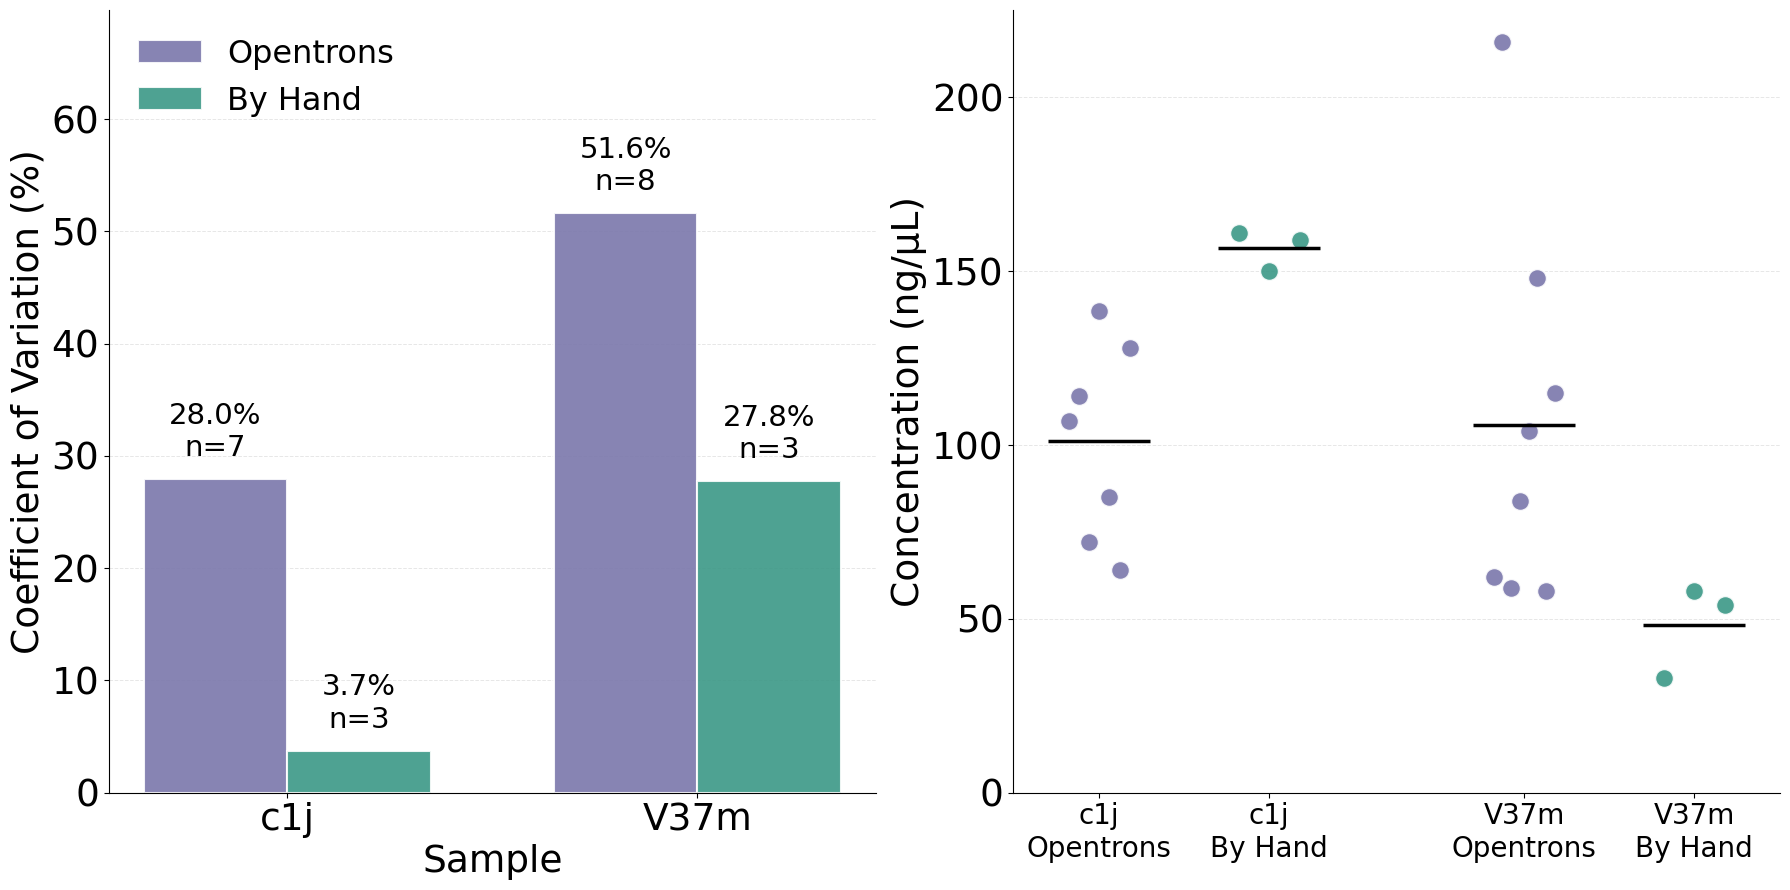

CV by sample and method (black bars on the right panel are the means):
    c1j  Opentrons: CV =  28.0%  (mean  101.2 ±  28.3 ng/μL, n=7)
    c1j    By Hand: CV =   3.7%  (mean  156.7 ±   5.9 ng/μL, n=3)
   V37m  Opentrons: CV =  51.6%  (mean  105.8 ±  54.6 ng/μL, n=8)
   V37m    By Hand: CV =  27.8%  (mean   48.3 ±  13.4 ng/μL, n=3)
  c1j: Opentrons CV is 7.5x the by-hand CV
  V37m: Opentrons CV is 1.9x the by-hand CV


In [21]:
# CV comparison plot: C1J and V37m, Opentrons vs By Hand
plot_samples = [s for s in focus_rows['Sample']]
methods = ['Opentrons', 'By Hand']
method_color = {'Opentrons': color_opentrons, 'By Hand': color_byhand}

cv_lookup = focus_cv_df.set_index(['Sample', 'Method'])

fig, (ax_cv, ax_pts) = plt.subplots(1, 2, figsize=(18, 9))

# --- Left panel: CV per sample per method ---
x = np.arange(len(plot_samples))
width = 0.35

for i, method in enumerate(methods):
    offset = (i - 0.5) * width
    cvs = [cv_lookup.loc[(s, method), 'CV'] for s in plot_samples]
    ns = [cv_lookup.loc[(s, method), 'n'] for s in plot_samples]
    bars = ax_cv.bar(x + offset, cvs, width,
                     label=method, alpha=0.9,
                     color=method_color[method], edgecolor='white', linewidth=1.5)
    for bar, cv, n in zip(bars, cvs, ns):
        ax_cv.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                   f'{cv:.1f}%\nn={n}', ha='center', va='bottom', fontsize=21)

ax_cv.set_ylabel('Coefficient of Variation (%)', fontsize=27)
ax_cv.set_xlabel('Sample', fontsize=27)
ax_cv.set_xticks(x)
ax_cv.set_xticklabels(plot_samples, fontsize=27)
ax_cv.tick_params(axis='y', labelsize=27)
ax_cv.set_ylim(0, max(focus_cv_df['CV']) * 1.35)
ax_cv.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax_cv.set_axisbelow(True)
ax_cv.legend(fontsize=23, frameon=False, loc='upper left')
ax_cv.spines['top'].set_visible(False)
ax_cv.spines['right'].set_visible(False)

# --- Right panel: the underlying replicate values behind each CV ---
positions, labels = [], []
for j, sample in enumerate(plot_samples):
    for i, method in enumerate(methods):
        pos = j * 2.5 + i
        positions.append(pos)
        labels.append(f'{sample}\n{method}')
        values = focus_values[(sample, method)]
        # Deterministic spread so points don't overlap (no RNG => stable figure)
        jitter = np.linspace(-0.18, 0.18, len(values)) if len(values) > 1 else np.zeros(1)
        ax_pts.scatter(pos + jitter, values, s=180, alpha=0.9,
                       color=method_color[method], edgecolor='white', linewidth=1.5,
                       zorder=3)
        mean = np.mean(values)
        ax_pts.hlines(mean, pos - 0.3, pos + 0.3, color='black', linewidth=2.5, zorder=4)

ax_pts.set_ylabel('Concentration (ng/μL)', fontsize=27)
ax_pts.set_xticks(positions)
ax_pts.set_xticklabels(labels, fontsize=20)
ax_pts.tick_params(axis='y', labelsize=27)
ax_pts.set_ylim(bottom=0)
ax_pts.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax_pts.set_axisbelow(True)
ax_pts.spines['top'].set_visible(False)
ax_pts.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../plots/CV_C1J_V37m.svg', dpi=1000, bbox_inches='tight')
plt.show()

print('CV by sample and method (black bars on the right panel are the means):')
for _, r in focus_cv_df.iterrows():
    print(f"  {r['Sample']:>5} {r['Method']:>10}: CV = {r['CV']:5.1f}%  "
          f"(mean {r['Mean']:6.1f} ± {r['SD']:5.1f} ng/μL, n={r['n']})")

for sample in plot_samples:
    o_cv = cv_lookup.loc[(sample, 'Opentrons'), 'CV']
    h_cv = cv_lookup.loc[(sample, 'By Hand'), 'CV']
    print(f"  {sample}: Opentrons CV is {o_cv / h_cv:.1f}x the by-hand CV")

## Sensitivity analysis: effect of dropping the O3 round on CV

O3 is the lowest-yielding Opentrons round (mean ~54 ng/μL vs 85-117 for the others), so it
may be inflating the Opentrons CV. Below, the whole CV analysis is repeated with O3 excluded
and compared like-for-like against the full dataset. By-hand replicates are untouched and act
as a control — their CV should not move.

Only samples that keep at least 2 Opentrons replicates *after* dropping O3 are compared, so
both variants are computed on the same set of samples.

In [22]:
# Recompute CV with an arbitrary set of replicate columns, so the analysis can be
# repeated with a round left out.
DROP_ROUND = 'O3'
O_COLS_DROPPED = [c for c in O_COLS if c != DROP_ROUND]


def cv_table(o_cols, h_cols, label):
    """CV per sample per method for the given replicate columns."""
    rows = []
    for _, row in df.iterrows():
        for method, cols in [('Opentrons', o_cols), ('By Hand', h_cols)]:
            values = reps(row, cols)
            if len(values) < 2:  # CV needs at least 2 replicates
                continue
            mean = np.mean(values)
            sd = np.std(values, ddof=1)
            rows.append({
                'Sample': row['Sample'],
                'Method': method,
                'Dataset': label,
                'n': len(values),
                'Mean': mean,
                'SD': sd,
                'CV': (sd / mean) * 100 if mean > 0 else np.nan,
            })
    return pd.DataFrame(rows)


cv_full = cv_table(O_COLS, H_COLS, 'All rounds')
cv_dropped = cv_table(O_COLS_DROPPED, H_COLS, f'Without {DROP_ROUND}')

# Restrict both to the sample/method pairs present in each, so the comparison is paired
keys_full = set(map(tuple, cv_full[['Sample', 'Method']].values))
keys_dropped = set(map(tuple, cv_dropped[['Sample', 'Method']].values))
shared_keys = keys_full & keys_dropped

lost = sorted(s for s, m in keys_full - keys_dropped)
if lost:
    print(f"Dropped below 2 replicates once {DROP_ROUND} is removed, so excluded: {lost}")

def _keep(frame):
    mask = [tuple(k) in shared_keys for k in frame[['Sample', 'Method']].values]
    return frame[mask]

cv_compare = pd.concat([_keep(cv_full), _keep(cv_dropped)], ignore_index=True)

# Per-sample delta, Opentrons only (by-hand values are identical by construction)
delta = (cv_compare[cv_compare['Method'] == 'Opentrons']
         .pivot(index='Sample', columns='Dataset', values='CV'))
delta['Delta'] = delta[f'Without {DROP_ROUND}'] - delta['All rounds']
delta = delta.sort_values('Delta')
delta

Dataset,All rounds,Without O3,Delta
Sample,,,
u1d,50.035951,34.830779,-15.205171
V37m,51.647755,49.233908,-2.413847
c1j,27.962192,26.022092,-1.940101
P1d,53.688119,53.688119,0.000000
t1d,55.295968,62.895153,7.599185


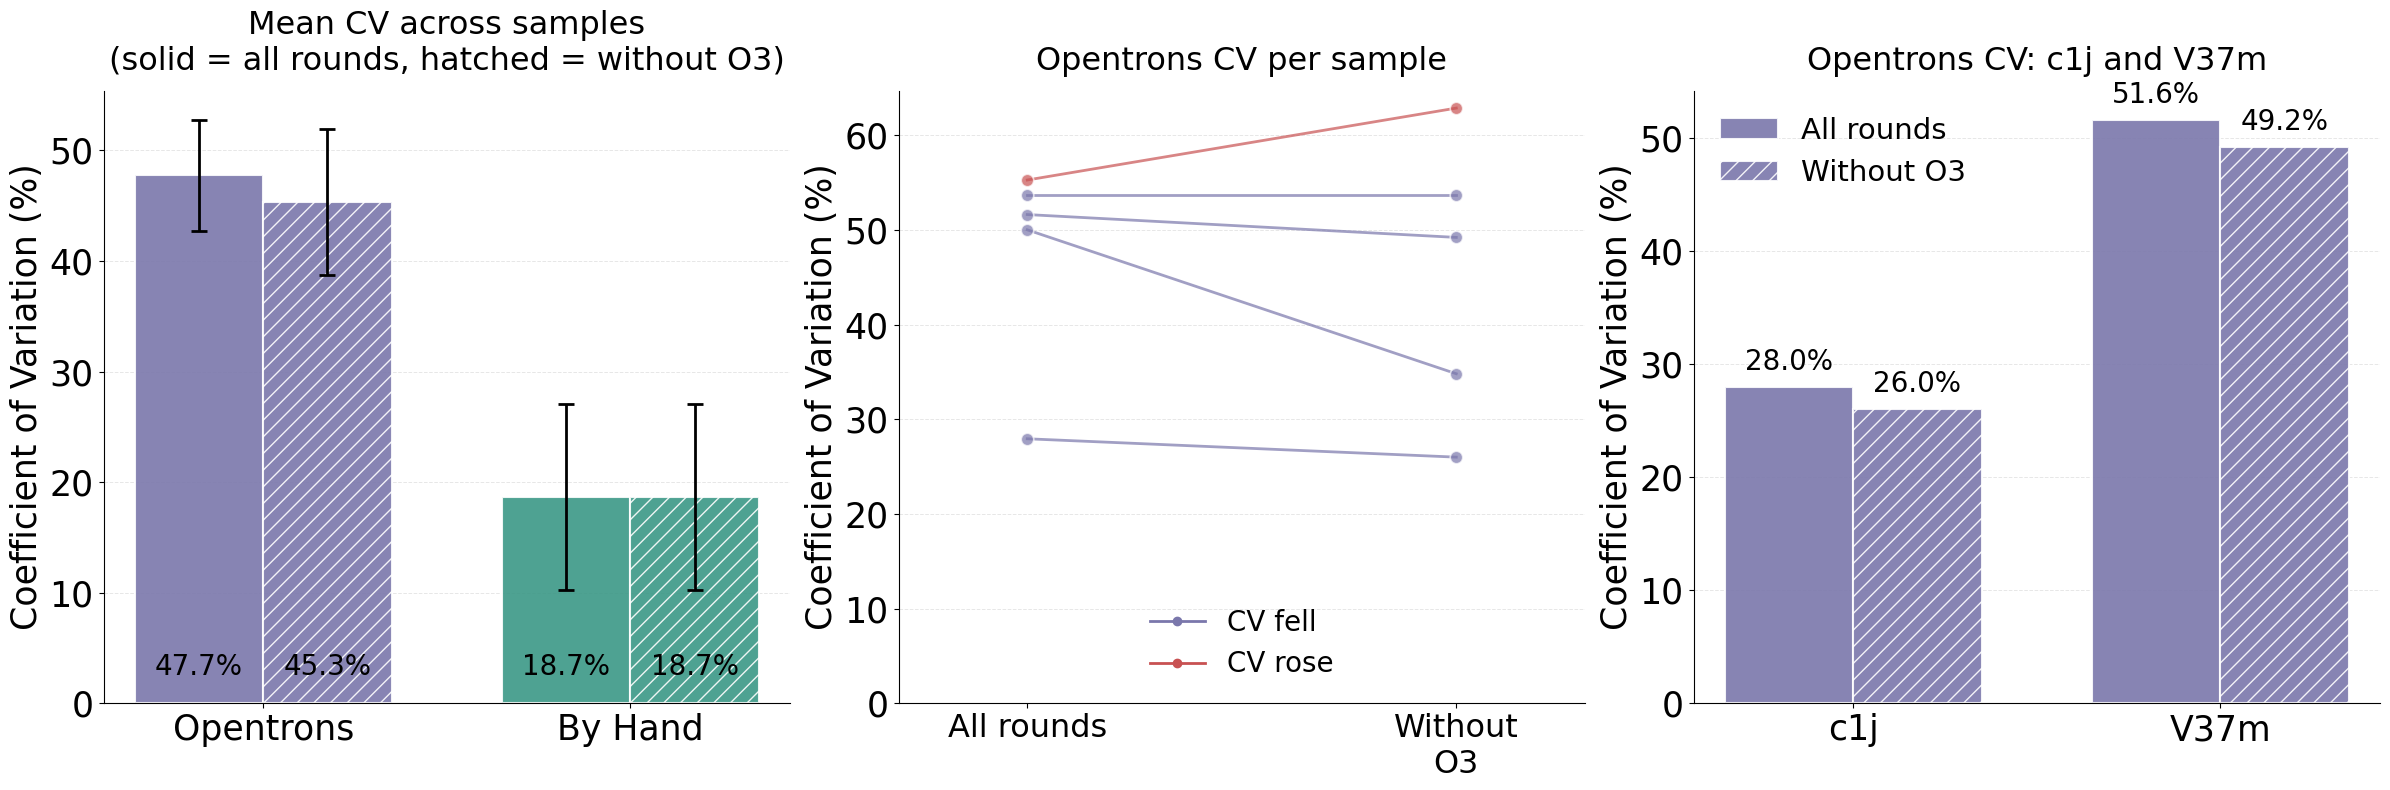

Effect of removing O3 (n = 5 samples with Opentrons replicates):

   Opentrons:  47.7% ->  45.3%  ( -2.4 pp)
     By Hand:  18.7% ->  18.7%  ( +0.0 pp)

  CV fell for 3 samples, rose for 1, unchanged for 1 (no O3 value) out of 5
  Median change among the 4 samples that actually had O3: -2.2 pp

  Focus samples:
      c1j:  28.0% ->  26.0% ( -1.9 pp)
     V37m:  51.6% ->  49.2% ( -2.4 pp)


In [23]:
# Effect of dropping O3 on CV: aggregate, per sample, and for the two focus samples
datasets = ['All rounds', f'Without {DROP_ROUND}']
methods = ['Opentrons', 'By Hand']
method_color = {'Opentrons': color_opentrons, 'By Hand': color_byhand}

fig, (ax_agg, ax_paired, ax_focus) = plt.subplots(1, 3, figsize=(24, 8))

# --- Panel 1: aggregate mean CV per method, with and without O3 ---
x = np.arange(len(methods))
width = 0.35
for i, dataset in enumerate(datasets):
    means, sds = [], []
    for method in methods:
        cvs = cv_compare[(cv_compare['Method'] == method) &
                         (cv_compare['Dataset'] == dataset)]['CV'].values
        means.append(np.mean(cvs))
        sds.append(np.std(cvs, ddof=1) / np.sqrt(len(cvs)))  # SEM of the mean CV
    bars = ax_agg.bar(x + (i - 0.5) * width, means, width, yerr=sds,
                      label=dataset, alpha=0.9,
                      color=[method_color[m] for m in methods],
                      hatch='' if i == 0 else '//',
                      edgecolor='white', linewidth=1.5, capsize=6,
                      error_kw={'linewidth': 2, 'elinewidth': 2, 'capthick': 2})
    for bar, mean in zip(bars, means):
        ax_agg.text(bar.get_x() + bar.get_width() / 2, 2,
                    f'{mean:.1f}%', ha='center', va='bottom', fontsize=20)

ax_agg.set_title(f'Mean CV across samples\n(solid = all rounds, hatched = without {DROP_ROUND})',
                 fontsize=23, pad=15)
ax_agg.set_ylabel('Coefficient of Variation (%)', fontsize=25)
ax_agg.set_xticks(x)
ax_agg.set_xticklabels(methods, fontsize=25)
ax_agg.tick_params(axis='y', labelsize=25)
ax_agg.set_ylim(bottom=0)
ax_agg.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax_agg.set_axisbelow(True)
ax_agg.spines['top'].set_visible(False)
ax_agg.spines['right'].set_visible(False)

# --- Panel 2: paired per-sample change in Opentrons CV ---
for sample, row in delta.iterrows():
    before, after = row['All rounds'], row[f'Without {DROP_ROUND}']
    ax_paired.plot([0, 1], [before, after],
                   color=color_opentrons if after <= before else apc.palettes.primary[9],
                   linewidth=2, alpha=0.7, marker='o', markersize=9,
                   markeredgecolor='white', markeredgewidth=1.2, zorder=3)

from matplotlib.lines import Line2D
ax_paired.legend(handles=[
    Line2D([0], [0], color=color_opentrons, linewidth=2, marker='o', label='CV fell'),
    Line2D([0], [0], color=apc.palettes.primary[9], linewidth=2, marker='o', label='CV rose'),
], fontsize=20, frameon=False, loc='lower center')  # lower centre is clear of the per-sample lines

ax_paired.set_title('Opentrons CV per sample', fontsize=23, pad=15)
ax_paired.set_ylabel('Coefficient of Variation (%)', fontsize=25)
ax_paired.set_xticks([0, 1])
ax_paired.set_xticklabels(['All rounds', f'Without\n{DROP_ROUND}'], fontsize=23)
ax_paired.set_xlim(-0.3, 1.3)
ax_paired.tick_params(axis='y', labelsize=25)
ax_paired.set_ylim(bottom=0)
ax_paired.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax_paired.set_axisbelow(True)
ax_paired.spines['top'].set_visible(False)
ax_paired.spines['right'].set_visible(False)

# --- Panel 3: the two focus samples ---
focus_plot = [s for s in focus_rows['Sample'] if s in delta.index]
x_f = np.arange(len(focus_plot))
for i, dataset in enumerate(datasets):
    col = 'All rounds' if i == 0 else f'Without {DROP_ROUND}'
    vals = [delta.loc[s, col] for s in focus_plot]
    bars = ax_focus.bar(x_f + (i - 0.5) * width, vals, width,
                        label=dataset, alpha=0.9, color=color_opentrons,
                        hatch='' if i == 0 else '//',
                        edgecolor='white', linewidth=1.5)
    for bar, v in zip(bars, vals):
        ax_focus.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                      f'{v:.1f}%', ha='center', va='bottom', fontsize=20)

ax_focus.set_title(f'Opentrons CV: {" and ".join(focus_plot)}', fontsize=23, pad=15)
ax_focus.set_ylabel('Coefficient of Variation (%)', fontsize=25)
ax_focus.set_xticks(x_f)
ax_focus.set_xticklabels(focus_plot, fontsize=25)
ax_focus.tick_params(axis='y', labelsize=25)
ax_focus.set_ylim(bottom=0)
ax_focus.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax_focus.set_axisbelow(True)
ax_focus.legend(fontsize=21, frameon=False, loc='upper left')
ax_focus.spines['top'].set_visible(False)
ax_focus.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f'../plots/CV_without_{DROP_ROUND}.svg', dpi=1000, bbox_inches='tight')
plt.show()

# --- Summary numbers ---
print(f"Effect of removing {DROP_ROUND} (n = {len(delta)} samples with Opentrons replicates):\n")
for method in methods:
    before = cv_compare[(cv_compare['Method'] == method) &
                        (cv_compare['Dataset'] == 'All rounds')]['CV'].mean()
    after = cv_compare[(cv_compare['Method'] == method) &
                       (cv_compare['Dataset'] == f'Without {DROP_ROUND}')]['CV'].mean()
    print(f"  {method:>10}: {before:5.1f}% -> {after:5.1f}%  ({after - before:+5.1f} pp)")

fell = (delta['Delta'] < 0).sum()
rose = (delta['Delta'] > 0).sum()
unchanged = len(delta) - fell - rose  # samples that had no O3 measurement anyway
print(f"\n  CV fell for {fell} samples, rose for {rose}, unchanged for {unchanged} "
      f"(no {DROP_ROUND} value) out of {len(delta)}")
affected = delta[delta['Delta'] != 0]
print(f"  Median change among the {len(affected)} samples that actually had {DROP_ROUND}: "
      f"{affected['Delta'].median():+.1f} pp")

print(f"\n  Focus samples:")
for s in focus_plot:
    r = delta.loc[s]
    print(f"    {s:>5}: {r['All rounds']:5.1f}% -> {r[f'Without {DROP_ROUND}']:5.1f}% "
          f"({r['Delta']:+5.1f} pp)")

## Variation suite: methods compared on samples with >=3 replicates each

Restricted to samples that carry at least 3 replicates by *both* methods, so every
comparison below is like-for-like. Two replicate sets are computed for each sample:

- **Matched n=3** - the first 3 replicates of each method. This is the primary comparison,
  because most variation metrics depend on how many replicates went into them and the
  Opentrons series runs to 7-8 replicates for some samples while by-hand is always 3.
- **All replicates** - everything available, shown alongside so nothing is hidden.


In [24]:
# Samples with at least 3 replicates by BOTH methods
MIN_REPS = 3

strict = []
for _, row in df.iterrows():
    o_values, h_values = reps(row, O_COLS), reps(row, H_COLS)
    if len(o_values) >= MIN_REPS and len(h_values) >= MIN_REPS:
        strict.append({'Sample': row['Sample'], 'Opentrons': o_values, 'By Hand': h_values})

strict_samples = [s['Sample'] for s in strict]
replicates = {(s['Sample'], m): s[m] for s in strict for m in ('Opentrons', 'By Hand')}

print(f"Samples with >={MIN_REPS} replicates by both methods: {strict_samples}")
for s in strict:
    print(f"  {s['Sample']:>5}: Opentrons n={len(s['Opentrons'])} {s['Opentrons']}")
    print(f"  {'':>5}  By Hand   n={len(s['By Hand'])} {s['By Hand']}")


def variation_metrics(values):
    """Spread of one replicate set, as several complementary metrics.

    All the relative metrics are expressed as % so the two methods can be compared
    despite their different yield levels.
    """
    v = np.asarray(values, dtype=float)
    n = len(v)
    mean, med = v.mean(), np.median(v)
    sd = v.std(ddof=1)
    log_sd = np.std(np.log(v), ddof=1)  # yields are positive and roughly multiplicative
    q75, q25 = np.percentile(v, [75, 25])
    mad = np.median(np.abs(v - med))
    return {
        'n': n,
        'Mean': mean,
        'SD': sd,
        'CV (%)': sd / mean * 100,
        'Geometric CV (%)': np.sqrt(np.exp(log_sd ** 2) - 1) * 100,
        'Relative range (%)': (v.max() - v.min()) / mean * 100,
        'Robust CV (%)': 1.4826 * mad / med * 100 if med > 0 else np.nan,
        'IQR / median (%)': (q75 - q25) / med * 100 if med > 0 else np.nan,
        'SEM (%)': sd / np.sqrt(n) / mean * 100,
    }


METRICS = ['CV (%)', 'Geometric CV (%)', 'Relative range (%)',
           'Robust CV (%)', 'IQR / median (%)', 'SEM (%)']

rows = []
for (sample, method), values in replicates.items():
    for variant, subset in [('Matched n=3', values[:MIN_REPS]), ('All replicates', values)]:
        rows.append({'Sample': sample, 'Method': method, 'Variant': variant,
                     **variation_metrics(subset)})

var_df = pd.DataFrame(rows)
var_df = var_df.sort_values(['Variant', 'Sample', 'Method']).reset_index(drop=True)
var_df.round(2)


Samples with >=3 replicates by both methods: ['c1j', 'P1d', 't1d', 'u1d', 'V37m']
    c1j: Opentrons n=7 [107.0, 114.0, 72.0, 138.5, 85.0, 64.0, 128.0]
         By Hand   n=3 [161.0, 150.0, 159.0]
    P1d: Opentrons n=3 [174.0, 62.5, 89.0]
         By Hand   n=3 [59.1, 144.0, 79.0]
    t1d: Opentrons n=4 [206.0, 40.0, 111.0, 175.0]
         By Hand   n=3 [53.0, 53.0, 64.0]
    u1d: Opentrons n=3 [105.0, 63.5, 37.0]
         By Hand   n=3 [65.0, 65.0, 69.0]
   V37m: Opentrons n=8 [62.0, 216.0, 59.0, 84.0, 104.0, 148.0, 58.0, 115.0]
         By Hand   n=3 [33.0, 58.0, 54.0]


,Sample,Method,Variant,n,Mean,SD,CV (%),Geometric CV (%),Relative range (%),Robust CV (%),IQR / median (%),SEM (%)
0,P1d,By Hand,All replicates,3,94.03,44.40,47.22,47.87,90.29,37.35,53.73,27.26
1,P1d,Opentrons,All replicates,3,108.50,58.25,53.69,55.73,102.76,44.14,62.64,31.00
2,V37m,By Hand,All replicates,3,48.33,13.43,27.78,31.44,51.72,10.98,23.15,16.04
3,V37m,Opentrons,All replicates,8,105.75,54.62,51.65,50.38,149.41,52.84,65.96,18.26
4,c1j,By Hand,All replicates,3,156.67,5.86,3.74,3.78,7.02,1.86,3.46,2.16
5,c1j,Opentrons,All replicates,7,101.21,28.30,27.96,30.04,73.61,30.48,39.72,10.57
6,t1d,By Hand,All replicates,3,56.67,6.35,11.21,10.92,19.41,0.00,10.38,6.47
7,t1d,Opentrons,All replicates,4,133.00,73.54,55.30,84.98,124.81,49.25,62.59,27.65
8,u1d,By Hand,All replicates,3,66.33,2.31,3.48,3.45,6.03,0.00,3.08,2.01
9,u1d,Opentrons,All replicates,3,68.50,34.27,50.04,55.92,99.27,61.87,53.54,28.89


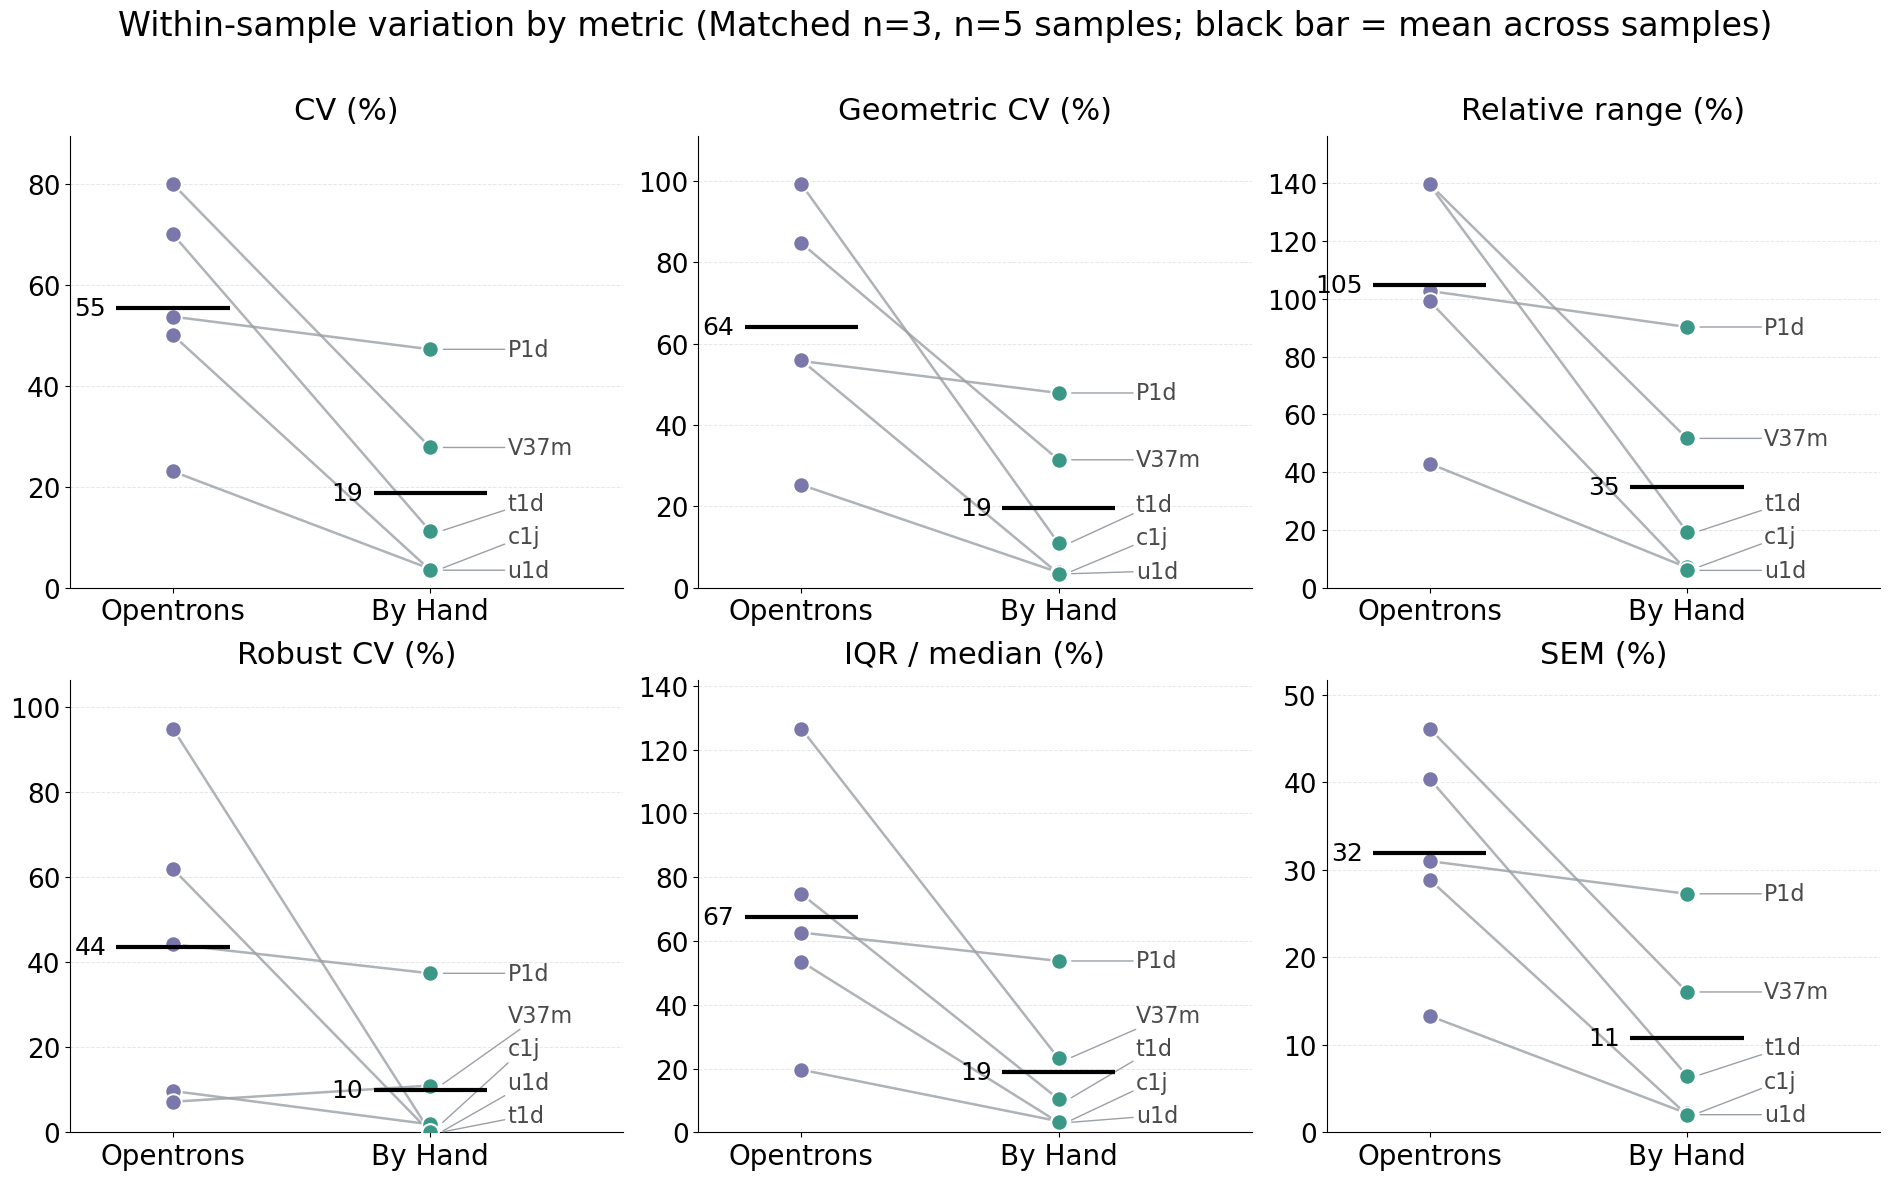

In [25]:
# Aggregate view 1: paired change per metric (each line is one sample)
VARIANT = 'Matched n=3'
methods = ['Opentrons', 'By Hand']
method_color = {'Opentrons': color_opentrons, 'By Hand': color_byhand}

sub = var_df[var_df['Variant'] == VARIANT].set_index(['Sample', 'Method'])

fig, axes = plt.subplots(2, 3, figsize=(19, 12))

for ax, metric in zip(axes.ravel(), METRICS):
    o_vals = np.array([sub.loc[(s, 'Opentrons'), metric] for s in strict_samples])
    h_vals = np.array([sub.loc[(s, 'By Hand'), metric] for s in strict_samples])

    for o_val, h_val in zip(o_vals, h_vals):
        ax.plot([0, 1], [o_val, h_val], color='#9AA0A6', linewidth=1.8, alpha=0.8, zorder=2)
    ax.scatter(np.zeros_like(o_vals), o_vals, s=140, color=color_opentrons,
               edgecolor='white', linewidth=1.4, zorder=3)
    ax.scatter(np.ones_like(h_vals), h_vals, s=140, color=color_byhand,
               edgecolor='white', linewidth=1.4, zorder=3)

    top = max(o_vals.max(), h_vals.max()) * 1.12
    ax.set_ylim(0, top)

    # Nudge overlapping sample labels apart so near-identical values stay readable. The gap is
    # one text line (1.4x the font height) converted to data units from the axes height, and the
    # lowest label is kept at least half a line above the x axis.
    label_size = 16
    axes_height_in = ax.get_position().height * fig.get_figheight()
    min_gap = top * (label_size * 1.4 / 72) / axes_height_in
    order = np.argsort(h_vals)
    last = -min_gap / 2
    for idx in order:
        y = max(h_vals[idx], last + min_gap)
        ax.annotate(strict_samples[idx], xy=(1.04, h_vals[idx]), xytext=(1.3, y), fontsize=label_size,
                    va='center', color='#4A4A4A',
                    arrowprops=dict(arrowstyle='-', color='#9AA0A6', linewidth=1, shrinkA=0, shrinkB=2))
        last = y

    # Group means as wide horizontal bars
    for i, values in enumerate([o_vals, h_vals]):
        m = values.mean()
        ax.hlines(m, i - 0.22, i + 0.22, color='black', linewidth=3, zorder=4)
        ax.text(i - 0.26, m, f'{m:.0f}', fontsize=18, va='center', ha='right', color='black')

    ax.set_title(metric, fontsize=22, pad=12)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(methods, fontsize=20)
    ax.set_xlim(-0.4, 1.75)
    ax.tick_params(axis='y', labelsize=19)
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle(f'Within-sample variation by metric ({VARIANT}, n={len(strict_samples)} samples; '
             'black bar = mean across samples)', fontsize=24)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('../plots/Variation_Aggregate_Paired.svg', dpi=1000, bbox_inches='tight')
plt.show()


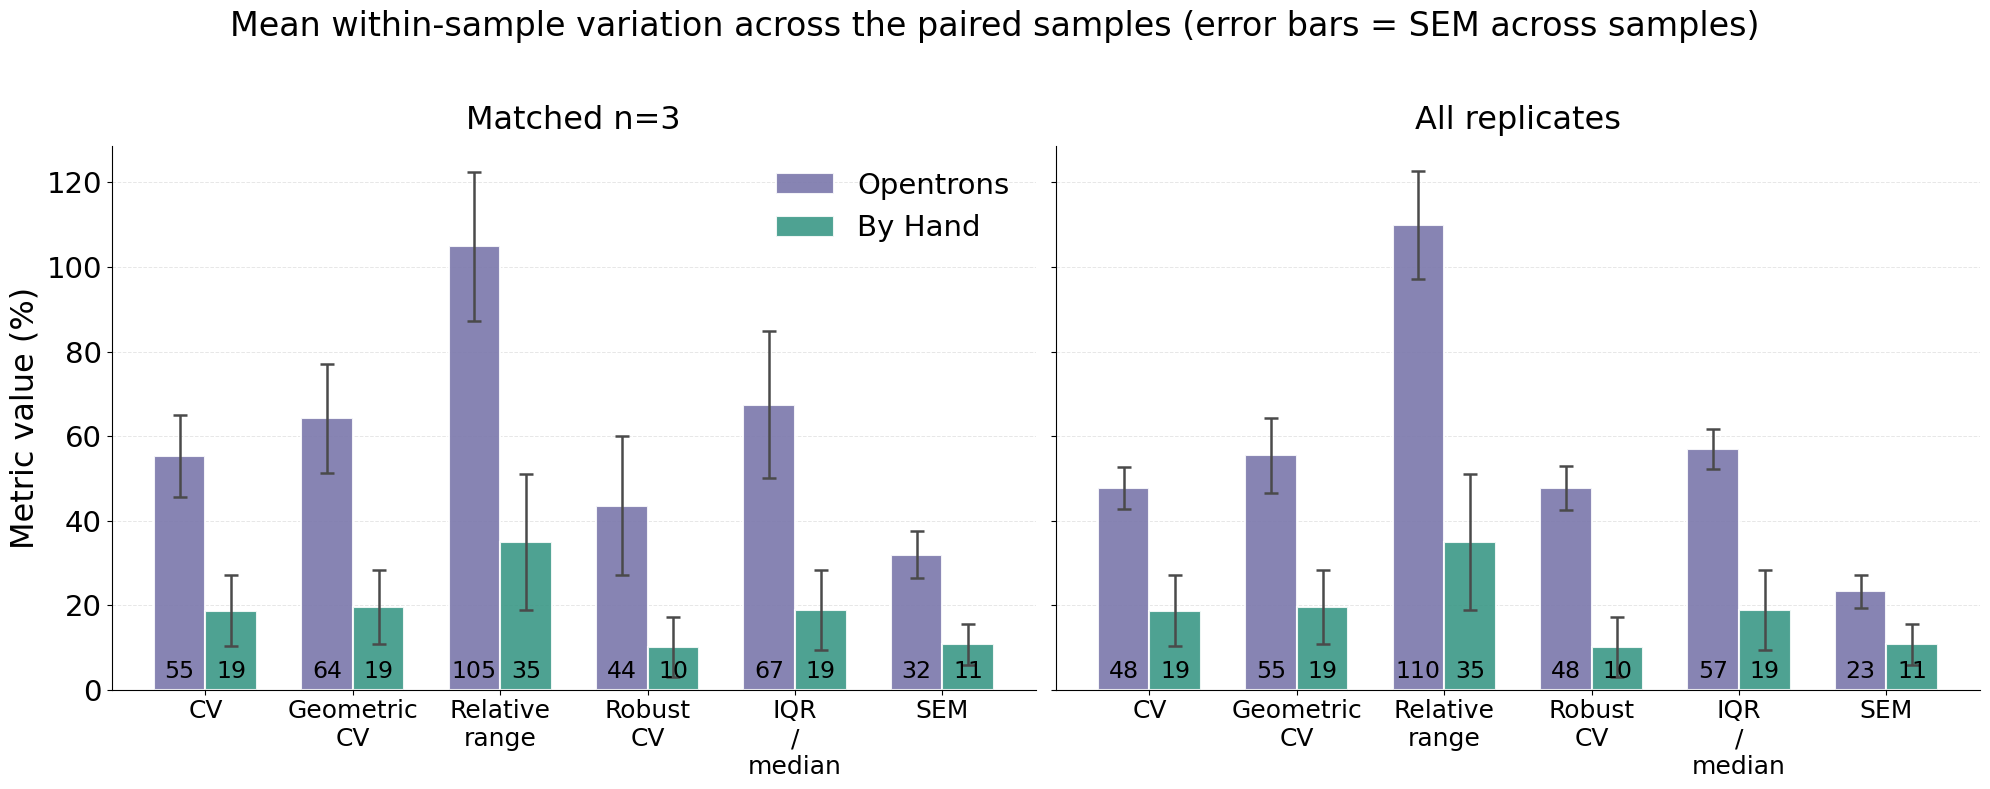

In [26]:
# Aggregate view 2: mean of each metric per method, matched vs all replicates
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)
x = np.arange(len(METRICS))
width = 0.35

for ax, variant in zip(axes, ['Matched n=3', 'All replicates']):
    frame = var_df[var_df['Variant'] == variant]
    for i, method in enumerate(methods):
        means = [frame[frame['Method'] == method][m].mean() for m in METRICS]
        sems = [frame[frame['Method'] == method][m].std(ddof=1) / np.sqrt(len(strict_samples))
                for m in METRICS]
        bars = ax.bar(x + (i - 0.5) * width, means, width, yerr=sems, capsize=5,
                      label=method, alpha=0.9, color=method_color[method],
                      edgecolor='white', linewidth=1.5,
                      error_kw={'linewidth': 1.8, 'elinewidth': 1.8, 'capthick': 1.8,
                                'ecolor': '#4A4A4A'})
        for bar, val in zip(bars, means):
            ax.text(bar.get_x() + bar.get_width() / 2, 1.5, f'{val:.0f}',
                    ha='center', va='bottom', fontsize=17)

    ax.set_title(variant, fontsize=23, pad=12)
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace(' (%)', '').replace(' ', '\n') for m in METRICS], fontsize=18)
    ax.tick_params(axis='y', labelsize=21)
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[0].set_ylabel('Metric value (%)', fontsize=23)
axes[0].legend(fontsize=21, frameon=False, loc='upper right')
fig.suptitle('Mean within-sample variation across the paired samples '
             '(error bars = SEM across samples)', fontsize=24)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('../plots/Variation_Aggregate_Metrics.svg', dpi=1000, bbox_inches='tight')
plt.show()


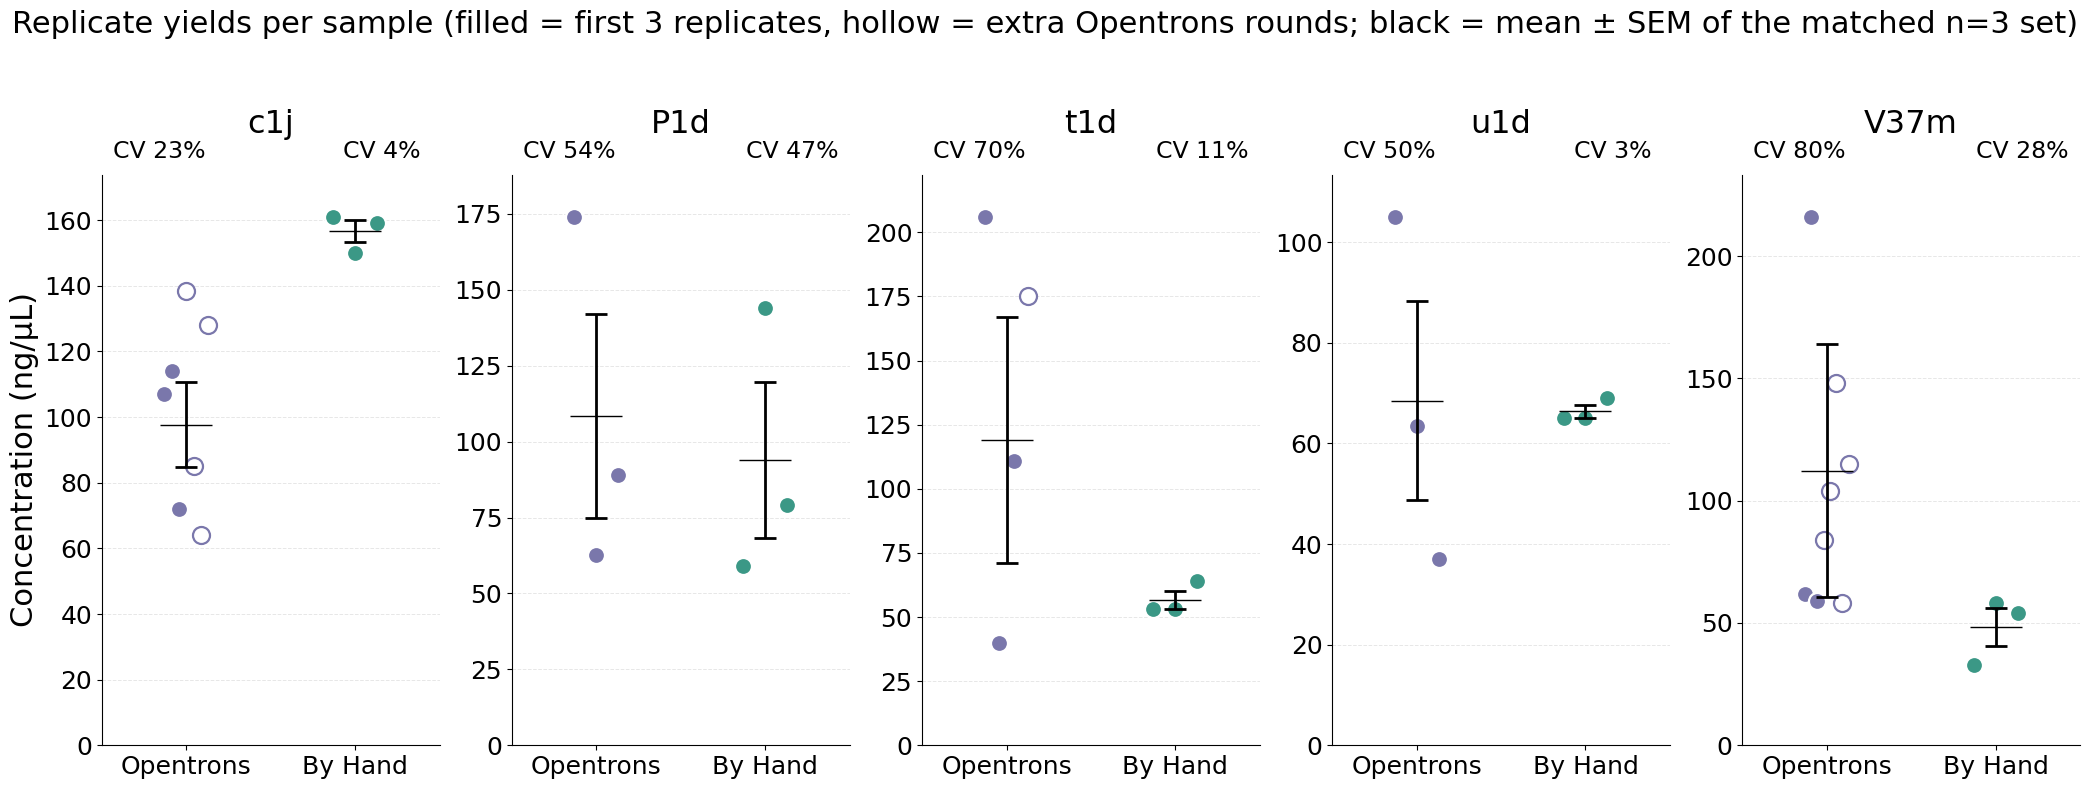

In [27]:
# Per-sample view 1: the raw replicates behind every comparison
n_samples = len(strict_samples)
fig, axes = plt.subplots(1, n_samples, figsize=(4.2 * n_samples, 8))
axes = np.atleast_1d(axes)

for ax, sample in zip(axes, strict_samples):
    panel_top = 0
    for i, method in enumerate(methods):
        values = np.asarray(replicates[(sample, method)], dtype=float)
        matched = values[:MIN_REPS]
        jitter = np.linspace(-0.13, 0.13, len(values)) if len(values) > 1 else np.zeros(1)
        # Replicates beyond the first 3 are drawn hollow: they are in "All replicates" only
        for j, (val, off) in enumerate(zip(values, jitter)):
            extra = j >= MIN_REPS
            ax.scatter(i + off, val, s=150,
                       facecolor='white' if extra else method_color[method],
                       edgecolor=method_color[method] if extra else 'white',
                       linewidth=1.6, zorder=3)
        # Mean +/- SEM of the matched n=3 set (CV still uses the SD)
        mean, sd = matched.mean(), matched.std(ddof=1)
        sem = sd / np.sqrt(len(matched))
        ax.errorbar(i, mean, yerr=sem, fmt='_', markersize=38, color='black',
                    linewidth=2, capsize=8, capthick=2, zorder=4)
        cv = sd / mean * 100
        ax.text(i / (len(methods) - 1) * 0.66 + 0.17, 1.02, f'CV {cv:.0f}%',
                transform=ax.transAxes, ha='center', va='bottom', fontsize=17)
        panel_top = max(panel_top, values.max(), mean + sem)

    ax.set_title(sample, fontsize=23, pad=30)
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(methods, fontsize=18)
    ax.set_xlim(-0.5, len(methods) - 0.5)
    ax.tick_params(axis='y', labelsize=18)
    ax.set_ylim(0, panel_top * 1.08)
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[0].set_ylabel('Concentration (ng/μL)', fontsize=22)
fig.suptitle('Replicate yields per sample (filled = first 3 replicates, hollow = extra '
             'Opentrons rounds; black = mean ± SEM of the matched n=3 set)', fontsize=22)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('../plots/Variation_PerSample_Replicates.svg', dpi=1000, bbox_inches='tight')
plt.show()


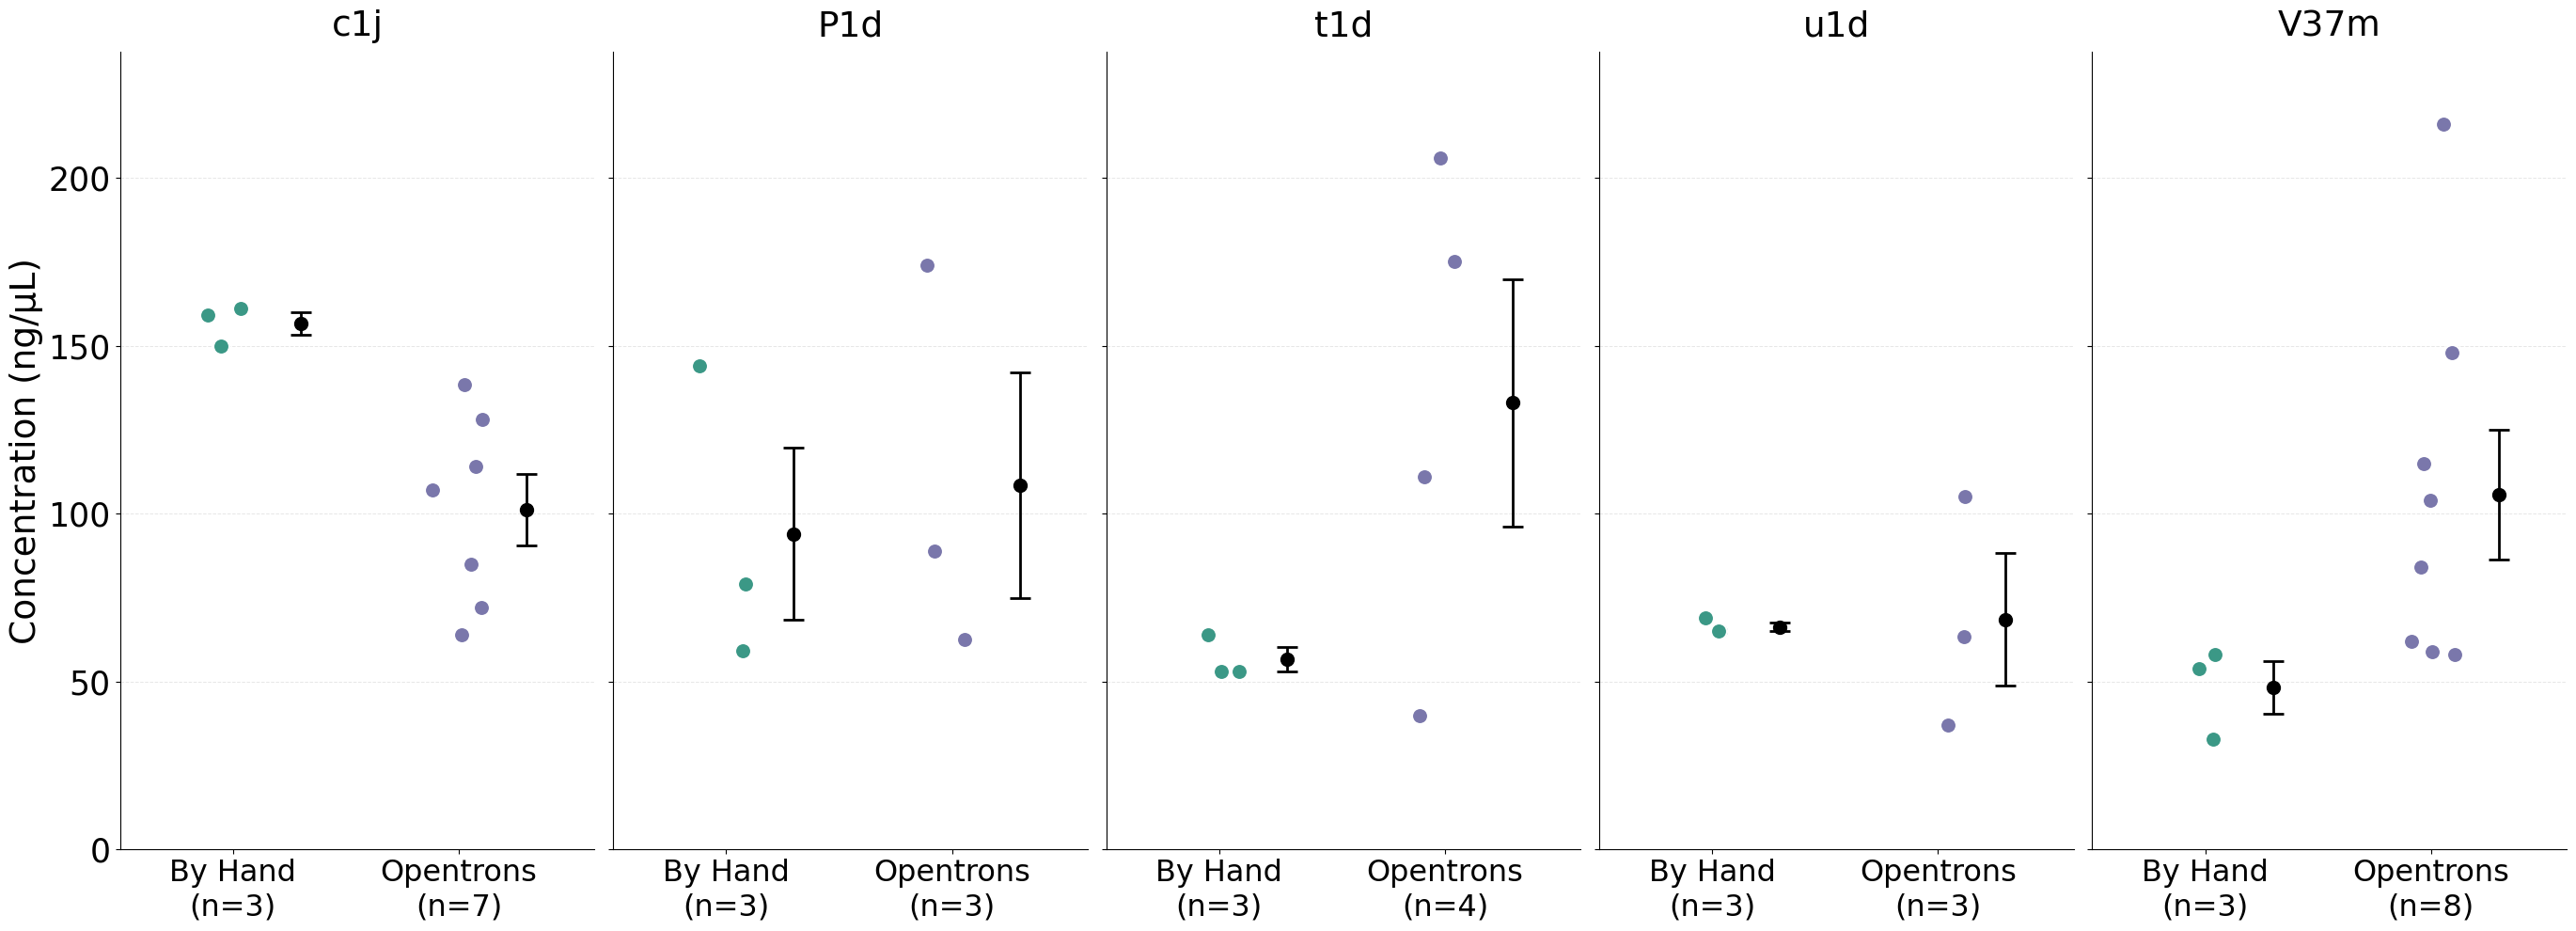

Mean ± SEM (ng/μL) and Welch t-test per plasmid:
    c1j: By Hand  156.7 ±   3.4 (n=3), Opentrons  101.2 ±  10.7 (n=7), Welch p = 0.002
    P1d: By Hand   94.0 ±  25.6 (n=3), Opentrons  108.5 ±  33.6 (n=3), Welch p = 0.751
    t1d: By Hand   56.7 ±   3.7 (n=3), Opentrons  133.0 ±  36.8 (n=4), Welch p = 0.129
    u1d: By Hand   66.3 ±   1.3 (n=3), Opentrons   68.5 ±  19.8 (n=3), Welch p = 0.923
   V37m: By Hand   48.3 ±   7.8 (n=3), Opentrons  105.8 ±  19.3 (n=8), Welch p = 0.023


In [28]:
# Yield by method for each plasmid with >= 3 replicates by both methods, in the same style as
# plots/c4j/C4J_YieldByMethod.svg: every prep as a point, with mean +/- SEM beside each group.
from scipy import stats

# Drawn by a function (one axis per plasmid, sharing y) so the combined figure reuses it
def plot_triplicate_yield(axes):
    jitter = np.random.default_rng(0)
    for ax, (_, row) in zip(np.atleast_1d(axes), df.iterrows()):
        groups = [(0, np.array(reps(row, H_COLS)), color_byhand),
                  (1, np.array(reps(row, O_COLS)), color_opentrons)]
        for x, vals, color in groups:
            ax.scatter(x + jitter.uniform(-0.12, 0.12, len(vals)), vals, s=150, color=color,
                       edgecolor='white', linewidth=1.5, zorder=3)
            ax.errorbar(x + 0.3, vals.mean(), yerr=stats.sem(vals), fmt='o', color='black',
                        markersize=10, capsize=8, elinewidth=2, capthick=2, zorder=4)

        ax.set_title(row['Sample'], fontsize=27, pad=12)
        ax.set_xticks([0, 1])
        ax.set_xticklabels([f'By Hand\n(n={len(groups[0][1])})', f'Opentrons\n(n={len(groups[1][1])})'], fontsize=23)
        ax.set_xlim(-0.5, 1.6)
        ax.tick_params(axis='y', labelsize=25)
        ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
        ax.set_axisbelow(True)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    axes[0].set_ylabel('Concentration (ng/μL)', fontsize=27)
    axes[0].set_ylim(0, df[O_COLS + H_COLS].max().max() * 1.1)


fig, axes = plt.subplots(1, len(df), figsize=(5.5 * len(df), 10), sharey=True)
plot_triplicate_yield(axes)
plt.tight_layout()
plt.savefig('../plots/Triplicates_YieldByMethod.svg', dpi=1000, bbox_inches='tight')
plt.show()

print("Mean ± SEM (ng/μL) and Welch t-test per plasmid:")
for _, row in df.iterrows():
    h, o = np.array(reps(row, H_COLS)), np.array(reps(row, O_COLS))
    p = stats.ttest_ind(o, h, equal_var=False).pvalue
    print(f"  {row['Sample']:>5}: By Hand {h.mean():6.1f} ± {stats.sem(h):5.1f} (n={len(h)}), "
          f"Opentrons {o.mean():6.1f} ± {stats.sem(o):5.1f} (n={len(o)}), Welch p = {p:.3f}")

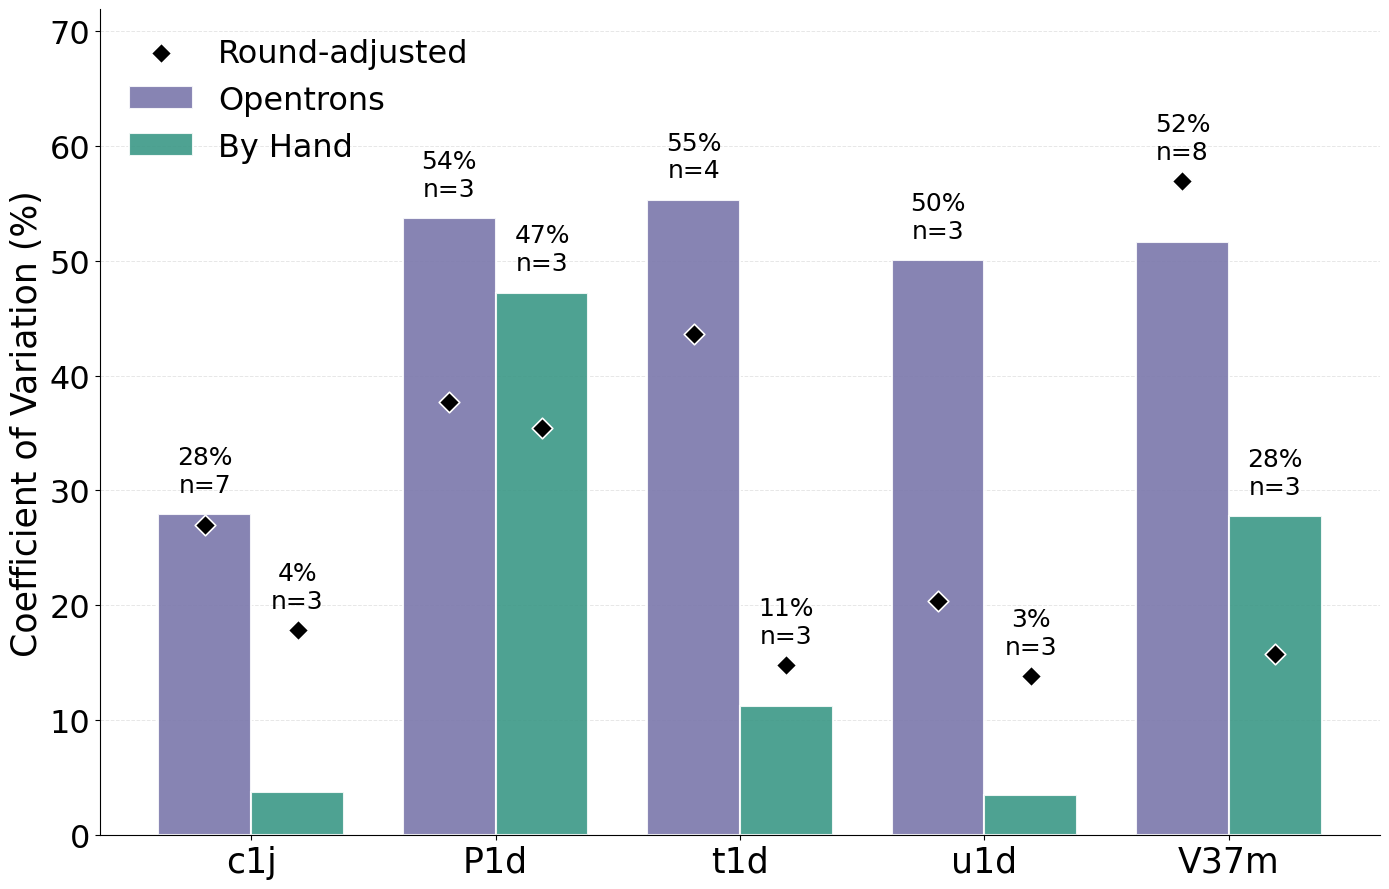

Round effects (log scale, relative to O1 / H1): {'O1': 0.0, 'O2': -0.37, 'O3': -0.63, 'O4': -0.11, 'O5': -0.31, 'O6': -0.28, 'O7': -0.4, 'O8': -0.09, 'H1': 0.0, 'H2': 0.28, 'H3': 0.2}
CV per plasmid, raw and round-adjusted, with F test of log-yield variance (Opentrons vs by hand):


,Opentrons,n_O,By Hand,n_H,p,Opentrons adj,By Hand adj,p adj
Sample,,,,,,,,
c1j,27.962,7,3.740,3,0.033,26.999,17.835,0.616
P1d,53.688,3,47.219,3,0.865,37.689,35.457,0.941
t1d,55.296,4,11.207,3,0.043,43.638,14.813,0.117
u1d,50.036,3,3.482,3,0.009,20.351,13.847,0.597
V37m,51.648,8,27.784,3,0.651,56.887,15.762,0.203


In [29]:
# CV for each plasmid separately, Opentrons vs by hand (all replicates; CV = SD / mean x 100).
# No error bars: with 3 preps the 95% CI on a single CV spans several-fold (e.g. P1d Opentrons
# 54% -> upper bound > 300%), so the per-plasmid test is reported in the legend instead: an F test of the log-yield
# variance, the same variance-ratio approach as GeometricCV_Overall.
#
# Culture round: every replicate comes from a different round, and these rounds were routine use of
# the manifold rather than a designed comparison, so no culture was split between methods. Round and
# method therefore cannot be fully separated. As a sensitivity check, a multiplicative round effect is
# estimated across plasmids (log yield = plasmid x method + round) and divided out before
# recomputing CV ("round-adjusted", diamonds). Rounds holding one plasmid (O8) are absorbed entirely,
# and rounds holding two (O5-O7) are poorly estimated, so the adjusted CVs are approximate.
from scipy import stats


def log_var_p(a, b):
    f = np.var(np.log(a), ddof=1) / np.var(np.log(b), ddof=1)
    d1, d2 = len(a) - 1, len(b) - 1
    return min(1.0, 2 * min(stats.f.sf(f, d1, d2), stats.f.cdf(f, d1, d2)))


# Round effects on the log scale; round levels are method-specific, with O1 and H1 as the baselines
# (the baseline choice does not affect a CV, which is scale-free within each plasmid)
round_long = df.melt(id_vars='Sample', value_vars=O_COLS + H_COLS, var_name='Round', value_name='Yield').dropna()
round_long['Method'] = np.where(round_long['Round'].str.startswith('O'), 'Opentrons', 'By Hand')
group_dummies = pd.get_dummies(round_long['Sample'] + ':' + round_long['Method'], dtype=float)
round_dummies = pd.get_dummies(round_long['Round'], dtype=float).drop(columns=['O1', 'H1'])
beta = np.linalg.lstsq(np.column_stack([group_dummies.values, round_dummies.values]),
                       np.log(round_long['Yield'].values), rcond=None)[0]
round_effect = pd.Series(beta[group_dummies.shape[1]:], index=round_dummies.columns) \
    .reindex(O_COLS + H_COLS, fill_value=0.0)


def round_adjusted(row, cols):
    return np.array([row[c] / np.exp(round_effect[c]) for c in cols if pd.notna(row[c])])


def cv_pct(x):
    return 100 * np.std(x, ddof=1) / np.mean(x)


cv_by_plasmid = []
for _, row in df.iterrows():
    o, h = np.array(reps(row, O_COLS)), np.array(reps(row, H_COLS))
    o_adj, h_adj = round_adjusted(row, O_COLS), round_adjusted(row, H_COLS)
    cv_by_plasmid.append({'Sample': row['Sample'],
                          'Opentrons': cv_pct(o), 'n_O': len(o),
                          'By Hand': cv_pct(h), 'n_H': len(h),
                          'p': log_var_p(o, h),
                          'Opentrons adj': cv_pct(o_adj), 'By Hand adj': cv_pct(h_adj),
                          'p adj': log_var_p(o_adj, h_adj)})
cv_by_plasmid = pd.DataFrame(cv_by_plasmid).set_index('Sample')


def plot_cv_by_plasmid(ax):
    x = np.arange(len(cv_by_plasmid))
    width = 0.38
    for offset, method, n_col, color in [(-width / 2, 'Opentrons', 'n_O', color_opentrons),
                                         (width / 2, 'By Hand', 'n_H', color_byhand)]:
        vals = cv_by_plasmid[method]
        ax.bar(x + offset, vals, width, color=color, alpha=0.9, edgecolor='white', linewidth=1.5, label=method)
        # Label sits above the bar or its round-adjusted diamond, whichever is higher
        for xi, v, v_adj, n in zip(x + offset, vals, cv_by_plasmid[f'{method} adj'], cv_by_plasmid[n_col]):
            ax.text(xi, max(v, v_adj) + 1.5, f'{v:.0f}%\nn={n}', ha='center', va='bottom', fontsize=18)
        # Round-adjusted CV as a diamond on each bar
        ax.scatter(x + offset, cv_by_plasmid[f'{method} adj'], marker='D', s=110, color='black',
                   edgecolor='white', linewidth=1.2, zorder=4,
                   label='Round-adjusted' if method == 'Opentrons' else None)

    # Per-plasmid p values: statistics go in the figure legend (reviewer request); values are printed by the analysis cells (table below)
    top = cv_by_plasmid[['Opentrons', 'By Hand', 'Opentrons adj', 'By Hand adj']].max(axis=1)

    ax.set_xticks(x)
    ax.set_xticklabels(cv_by_plasmid.index, fontsize=25)
    ax.set_ylabel('Coefficient of Variation (%)', fontsize=25)
    ax.tick_params(axis='y', labelsize=23)
    ax.set_ylim(0, top.max() + 15)
    ax.legend(fontsize=23, frameon=False, loc='upper left')
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


fig, ax = plt.subplots(figsize=(14, 9))
plot_cv_by_plasmid(ax)
plt.tight_layout()
plt.savefig('../plots/Triplicates_CVByPlasmid.svg', dpi=1000, bbox_inches='tight')
plt.show()

print("Round effects (log scale, relative to O1 / H1):", round_effect.round(2).to_dict())
print("CV per plasmid, raw and round-adjusted, with F test of log-yield variance (Opentrons vs by hand):")
cv_by_plasmid.round(3)

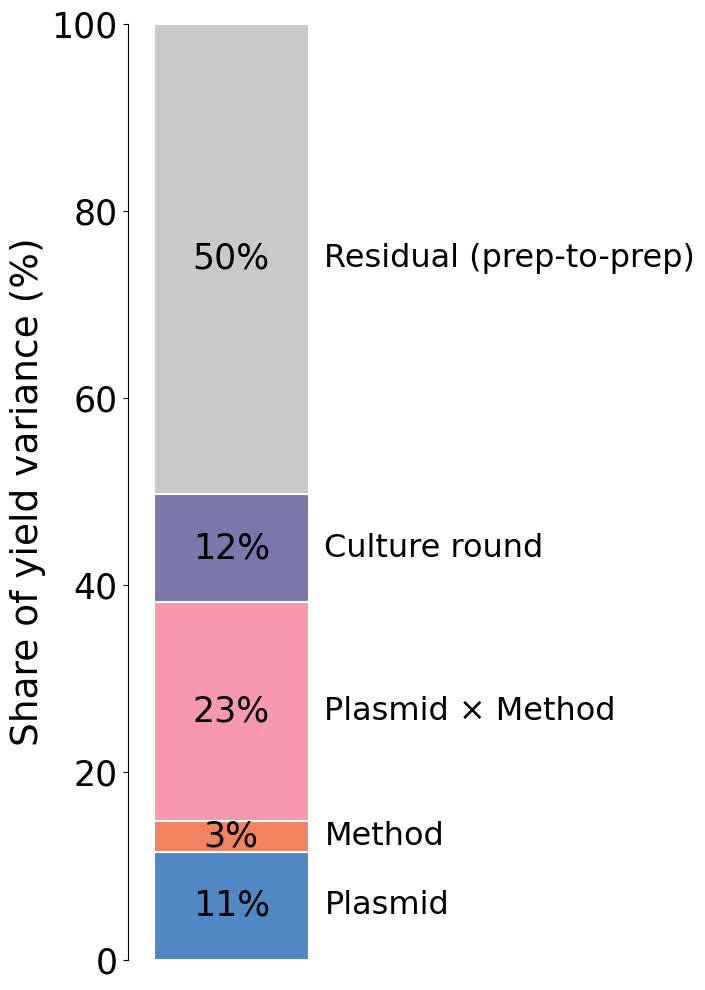

40 preps from 5 plasmids; sequential sums of squares:


,SS,df,Share (%),F,p
Term,,,,,
Plasmid,10307.832,4,11.481,1.198,0.341
Method,3012.748,1,3.356,1.401,0.250
Plasmid × Method,20947.154,4,23.331,2.435,0.079
Culture round,10348.399,9,11.526,0.535,0.833
Residual (prep-to-prep),45164.703,21,50.306,NaN,NaN


In [30]:
# Variance components for the plasmids with >= 3 replicates by both methods, in the same style as
# plots/c4j/C4J_VarianceComponents.svg. The design is unbalanced (3-8 preps per plasmid and method,
# rounds not shared between methods), so the shares are sequential sums of squares from nested
# least-squares fits rather than ANOVA mean-square components:
#   plasmid -> method -> plasmid x method -> culture round -> residual (prep-to-prep)
# Culture round levels are method-specific (O1-O8, H1-H3), so round is entered after method.
from scipy import stats

vc_long = df.melt(id_vars='Sample', value_vars=O_COLS + H_COLS, var_name='Round', value_name='Yield').dropna()
vc_long['Method'] = np.where(vc_long['Round'].str.startswith('O'), 'Opentrons', 'By Hand')
vc_long['PlasmidMethod'] = vc_long['Sample'] + ':' + vc_long['Method']
y = vc_long['Yield'].values


def dummies(col):
    return pd.get_dummies(vc_long[col], drop_first=True, dtype=float).values


terms = [('Plasmid', dummies('Sample')),
         ('Method', dummies('Method')),
         ('Plasmid × Method', dummies('PlasmidMethod')),
         ('Culture round', dummies('Round'))]

X = np.ones((len(y), 1))
rss_prev = ((y - y.mean()) ** 2).sum()
ss_total = rss_prev
rank_prev = 1
vc_rows = []
for name, D in terms:
    X = np.column_stack([X, D])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    rss = ((y - X @ beta) ** 2).sum()
    rank = np.linalg.matrix_rank(X)
    vc_rows.append({'Term': name, 'SS': rss_prev - rss, 'df': rank - rank_prev})
    rss_prev, rank_prev = rss, rank
df_res = len(y) - rank_prev
vc_rows.append({'Term': 'Residual (prep-to-prep)', 'SS': rss_prev, 'df': df_res})
vc_table = pd.DataFrame(vc_rows).set_index('Term')
vc_table['Share (%)'] = 100 * vc_table['SS'] / ss_total
ms_res = rss_prev / df_res
vc_table['F'] = (vc_table['SS'] / vc_table['df']) / ms_res
vc_table['p'] = [stats.f.sf(f, d, df_res) for f, d in zip(vc_table['F'], vc_table['df'])]
vc_table.loc['Residual (prep-to-prep)', ['F', 'p']] = np.nan

component_colors = [apc.palettes.primary[0], apc.palettes.primary[1], apc.palettes.primary[5],
                    apc.palettes.primary[4], '#C9C9C9']

fig, ax = plt.subplots(figsize=(7, 10))
bottom = 0
for (name, share), color in zip(vc_table['Share (%)'].items(), component_colors):
    ax.bar(0, share, bottom=bottom, color=color, edgecolor='white', linewidth=1.5, width=0.6)
    if share > 2:
        ax.text(0, bottom + share / 2, f'{share:.0f}%', ha='center', va='center', fontsize=25)
    ax.text(0.36, bottom + share / 2, name if share > 2 else f'{name} ({share:.0f}%)', ha='left', va='center', fontsize=23)
    bottom += share

ax.set_xlim(-0.4, 1.6)
ax.set_ylim(0, 100)
ax.set_xticks([])
ax.set_ylabel('Share of yield variance (%)', fontsize=27)
ax.tick_params(axis='y', labelsize=25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
plt.tight_layout()
plt.savefig('../plots/Triplicates_VarianceComponents.svg', dpi=1000, bbox_inches='tight')
plt.show()

print(f"{len(y)} preps from {vc_long['Sample'].nunique()} plasmids; sequential sums of squares:")
vc_table.round(3)

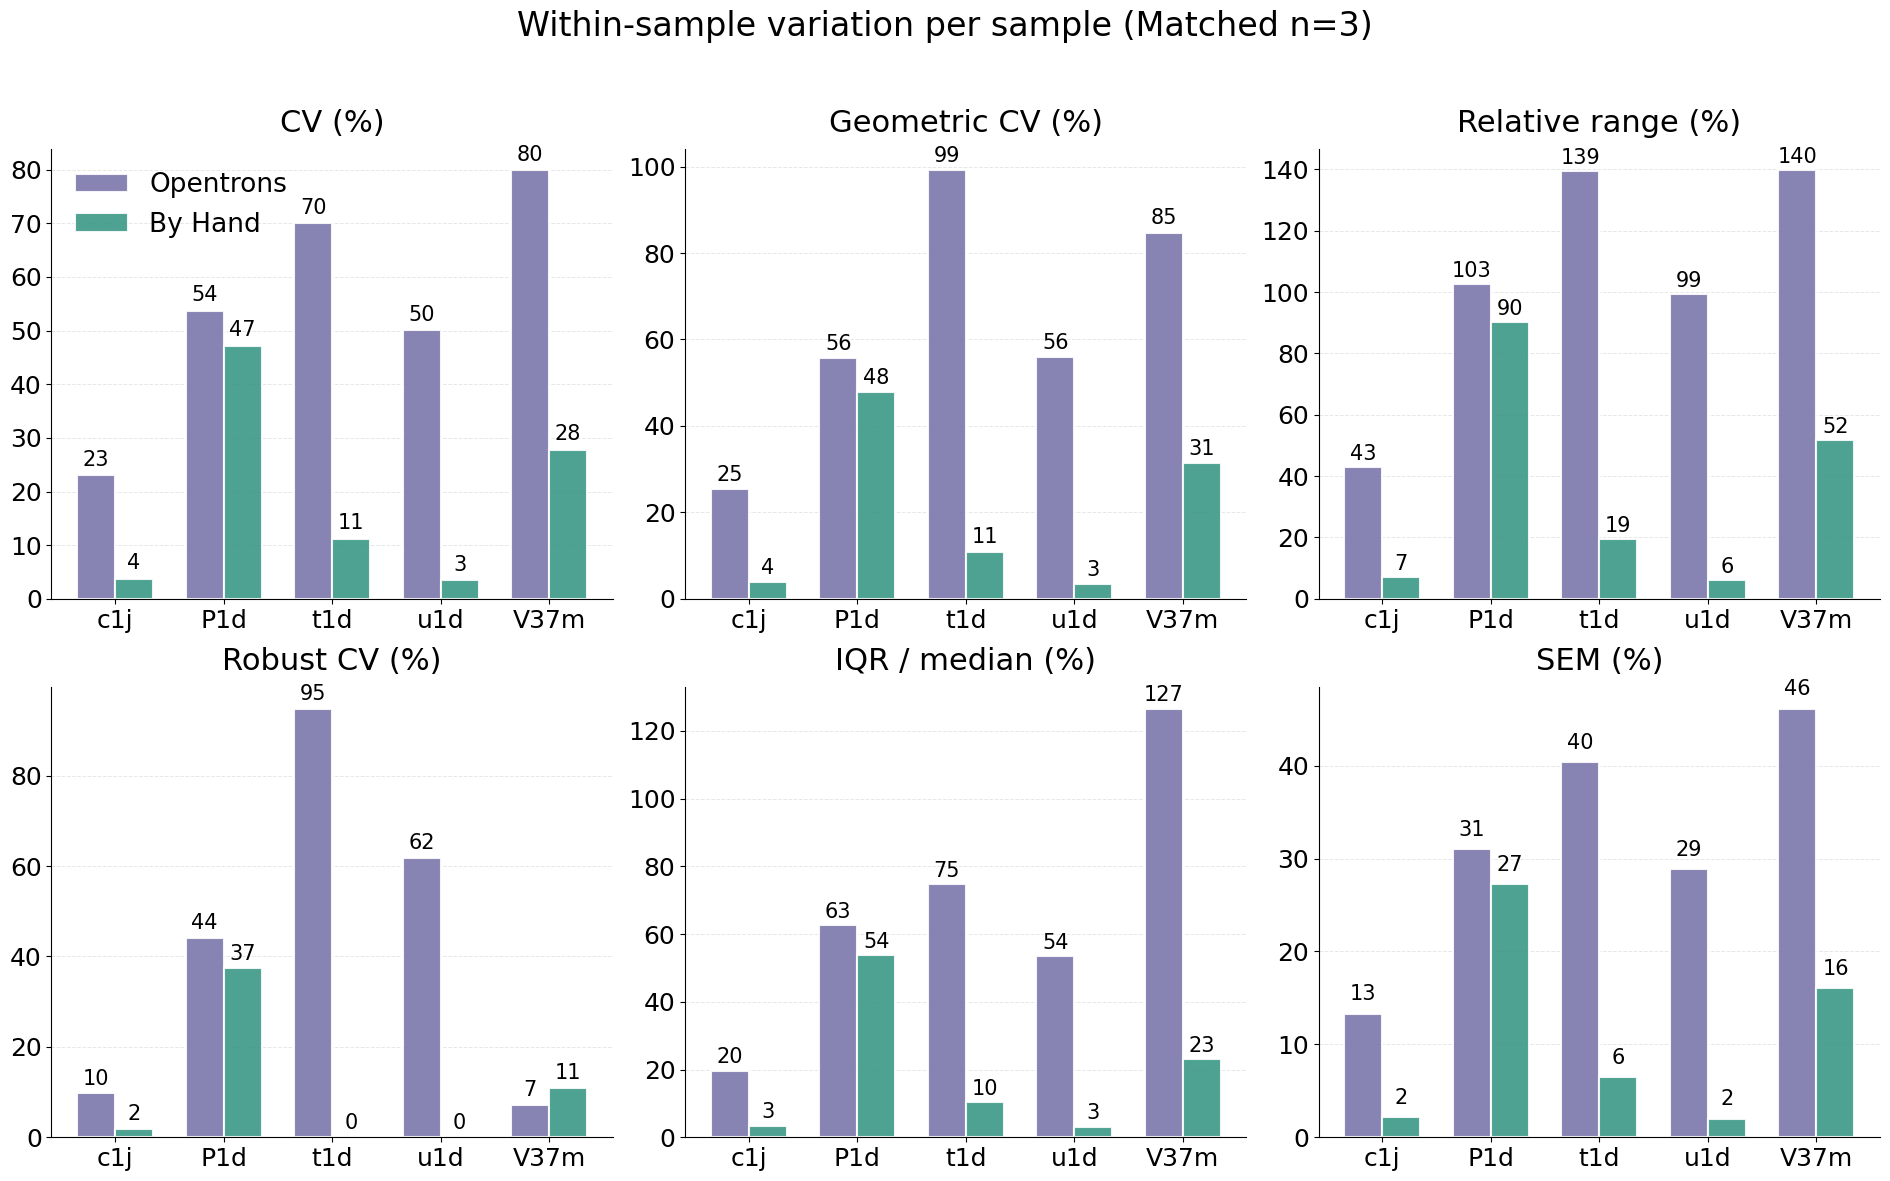

In [31]:
# Per-sample view 2: every metric, sample by sample
fig, axes = plt.subplots(2, 3, figsize=(19, 12))
x = np.arange(len(strict_samples))
width = 0.35

for ax, metric in zip(axes.ravel(), METRICS):
    for i, method in enumerate(methods):
        vals = [sub.loc[(s, method), metric] for s in strict_samples]
        bars = ax.bar(x + (i - 0.5) * width, vals, width, label=method, alpha=0.9,
                      color=method_color[method], edgecolor='white', linewidth=1.5)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                    f'{val:.0f}', ha='center', va='bottom', fontsize=15)

    ax.set_title(metric, fontsize=22, pad=12)
    ax.set_xticks(x)
    ax.set_xticklabels(strict_samples, fontsize=18)
    ax.tick_params(axis='y', labelsize=18)
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes.ravel()[0].legend(fontsize=19, frameon=False, loc='upper left')
fig.suptitle(f'Within-sample variation per sample ({VARIANT})', fontsize=24)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../plots/Variation_PerSample_Metrics.svg', dpi=1000, bbox_inches='tight')
plt.show()


In [32]:
# Do the two methods actually differ in variability? Paired tests on the matched n=3 sets.
print(f"Paired comparison across {len(strict_samples)} samples ({VARIANT})\n")
print(f"{'Metric':>20}  {'Opentrons':>10}  {'By Hand':>9}  {'Ratio':>6}  {'Wilcoxon p':>11}  "
      f"{'t-test p':>9}")

for metric in METRICS:
    o_vals = np.array([sub.loc[(s, 'Opentrons'), metric] for s in strict_samples])
    h_vals = np.array([sub.loc[(s, 'By Hand'), metric] for s in strict_samples])
    try:
        w_p = stats.wilcoxon(o_vals, h_vals).pvalue
    except ValueError:
        w_p = np.nan
    t_p = stats.ttest_rel(o_vals, h_vals).pvalue
    print(f"{metric:>20}  {o_vals.mean():10.1f}  {h_vals.mean():9.1f}  "
          f"{o_vals.mean() / h_vals.mean():6.2f}  {w_p:11.4f}  {t_p:9.4f}")

print(f"\nNote: with n={len(strict_samples)} paired samples the smallest attainable Wilcoxon "
      f"p-value is {2 / 2 ** len(strict_samples):.4f}, so this test cannot reach p<0.05 here.")

# Pooled within-sample variance on the log scale: one number per method, using every
# sample at once rather than averaging 5 noisy per-sample estimates.
print("\nPooled within-sample spread on the log scale (all replicates, samples pooled):")
for method in methods:
    ss, dof = 0.0, 0
    for sample in strict_samples:
        logs = np.log(np.asarray(replicates[(sample, method)], dtype=float))
        ss += ((logs - logs.mean()) ** 2).sum()
        dof += len(logs) - 1
    pooled_log_sd = np.sqrt(ss / dof)
    gcv = np.sqrt(np.exp(pooled_log_sd ** 2) - 1) * 100
    print(f"  {method:>10}: pooled log SD = {pooled_log_sd:.3f}  ->  geometric CV = {gcv:5.1f}%  "
          f"(df = {dof})")

# Variance ratio between methods, per sample (matched n=3, log scale)
print("\nPer-sample variance ratio (Opentrons/By Hand, log scale, matched n=3):")
for sample in strict_samples:
    o_log = np.log(np.asarray(replicates[(sample, 'Opentrons')][:MIN_REPS], dtype=float))
    h_log = np.log(np.asarray(replicates[(sample, 'By Hand')][:MIN_REPS], dtype=float))
    f_stat = o_log.var(ddof=1) / h_log.var(ddof=1)
    dfn = dfd = MIN_REPS - 1
    p = 2 * min(stats.f.cdf(f_stat, dfn, dfd), 1 - stats.f.cdf(f_stat, dfn, dfd))
    print(f"  {sample:>5}: F = {f_stat:7.2f}  p = {p:.3f}")


Paired comparison across 5 samples (Matched n=3)

              Metric   Opentrons    By Hand   Ratio   Wilcoxon p   t-test p
              CV (%)        55.3       18.7    2.96       0.0625     0.0222
    Geometric CV (%)        64.2       19.5    3.29       0.0625     0.0333
  Relative range (%)       104.9       34.9    3.01       0.0625     0.0241
       Robust CV (%)        43.5       10.0    4.34       0.1250     0.1550
    IQR / median (%)        67.4       18.8    3.60       0.0625     0.0470
             SEM (%)        31.9       10.8    2.96       0.0625     0.0222

Note: with n=5 paired samples the smallest attainable Wilcoxon p-value is 0.0625, so this test cannot reach p<0.05 here.

Pooled within-sample spread on the log scale (all replicates, samples pooled):
   Opentrons: pooled log SD = 0.491  ->  geometric CV =  52.2%  (df = 20)
     By Hand: pooled log SD = 0.251  ->  geometric CV =  25.5%  (df = 10)

Per-sample variance ratio (Opentrons/By Hand, log scale, matched n=

### Which metric to use

**Error bars: SEM throughout (decided 2026-11-02).** The paper's question is the mean yield each
method delivers, so every error bar on a mean (yield, or mean CV across samples) is ±1 SEM, not SD.
Confidence intervals stay where a figure shows a proportion or a single CV estimate.

**Variability comparisons:** where the methods' reproducibility is compared, the scale-free metric is
geometric CV (equivalently, SD of log yield), pooled across samples, with per-sample CV alongside.

Reasoning, metric by metric:

| Metric | Verdict |
|---|---|
| **Geometric CV** | **Best here.** Scale-free, and it matches how yields behave - spread grows with the mean, and a bad prep is a *fold* loss, not a fixed ng/μL loss. Pooling the log-scale variance across samples uses all 20 vs 10 degrees of freedom instead of averaging 5 noisy estimates. Pooled: **52.2% Opentrons vs 25.5% by hand**. |
| **CV** | Good, and more familiar. Same story (55% vs 19% at matched n=3). Use it if the audience expects CV; it only diverges from geometric CV when spread is large, which is exactly the Opentrons case. |
| **SD** | Avoid as the headline. It has units, so it scales with the yield level, and the two methods sit at different yield levels - it conflates "more variable" with "higher yielding". |
| **Relative range** | Avoid. Range grows mechanically with replicate count, so it is only interpretable at matched n, and it throws away everything except two points. |
| **Robust CV (MAD)** | Fails at n=3. With three values the MAD is just the middle absolute deviation, and it returns **exactly 0** for t1d and u1d by hand (values 53/53/64 and 65/65/69) - reporting zero variability is worse than reporting a noisy number. Robust metrics need n≥5-ish. |
| **IQR / median** | Same problem as MAD at n=3: quartiles from three points are interpolation artefacts. |
| **SEM** | **Default for all error bars.** SEM is the precision of the *mean* of a set of replicates, which is what the paper is about. Note it shrinks as replicates are added (V37m has 8 Opentrons vs 3 by-hand preps), so it describes how well the mean is known, not how variable single preps are; use CV / geometric CV for that. |

**What the data say.** Opentrons is roughly 3x more variable than by hand on every scale-free
metric at matched n=3 (CV 55% vs 19%; geometric CV 64% vs 19%), and 2x on the pooled log-scale
estimate that uses all replicates (52% vs 26%).

**How hard to push that claim.** With only 5 paired samples, the Wilcoxon signed-rank test cannot
produce a p below 0.0625 no matter how clean the separation, so the paired t-tests (p ≈ 0.02-0.03
for CV and geometric CV) are doing the work, and they assume normality of a 5-point difference.
Per-sample F-tests on the log-scale variances reject for 3 of 5 samples (u1d p=0.009, t1d p=0.034,
c1j p=0.045) but the F-test at n=3 is fragile.

**The real confound.** The Opentrons replicates are separate culture rounds run across different
days, while the by-hand triplicates come from far fewer sessions. Some of the gap is therefore
day-to-day biological and culture variation, not pipetting. To attribute the difference to the
method itself, the comparison needs by-hand replicates spread over the same rounds as the
Opentrons ones.


### Headline figure: overall geometric CV

Pooling the within-sample log-scale variances gives one variability number per method that
uses every replicate, rather than averaging five noisy per-sample estimates. The right-hand
panel repeats it with each method capped at 3 replicates, confirming the gap is not an
artefact of the longer Opentrons series.


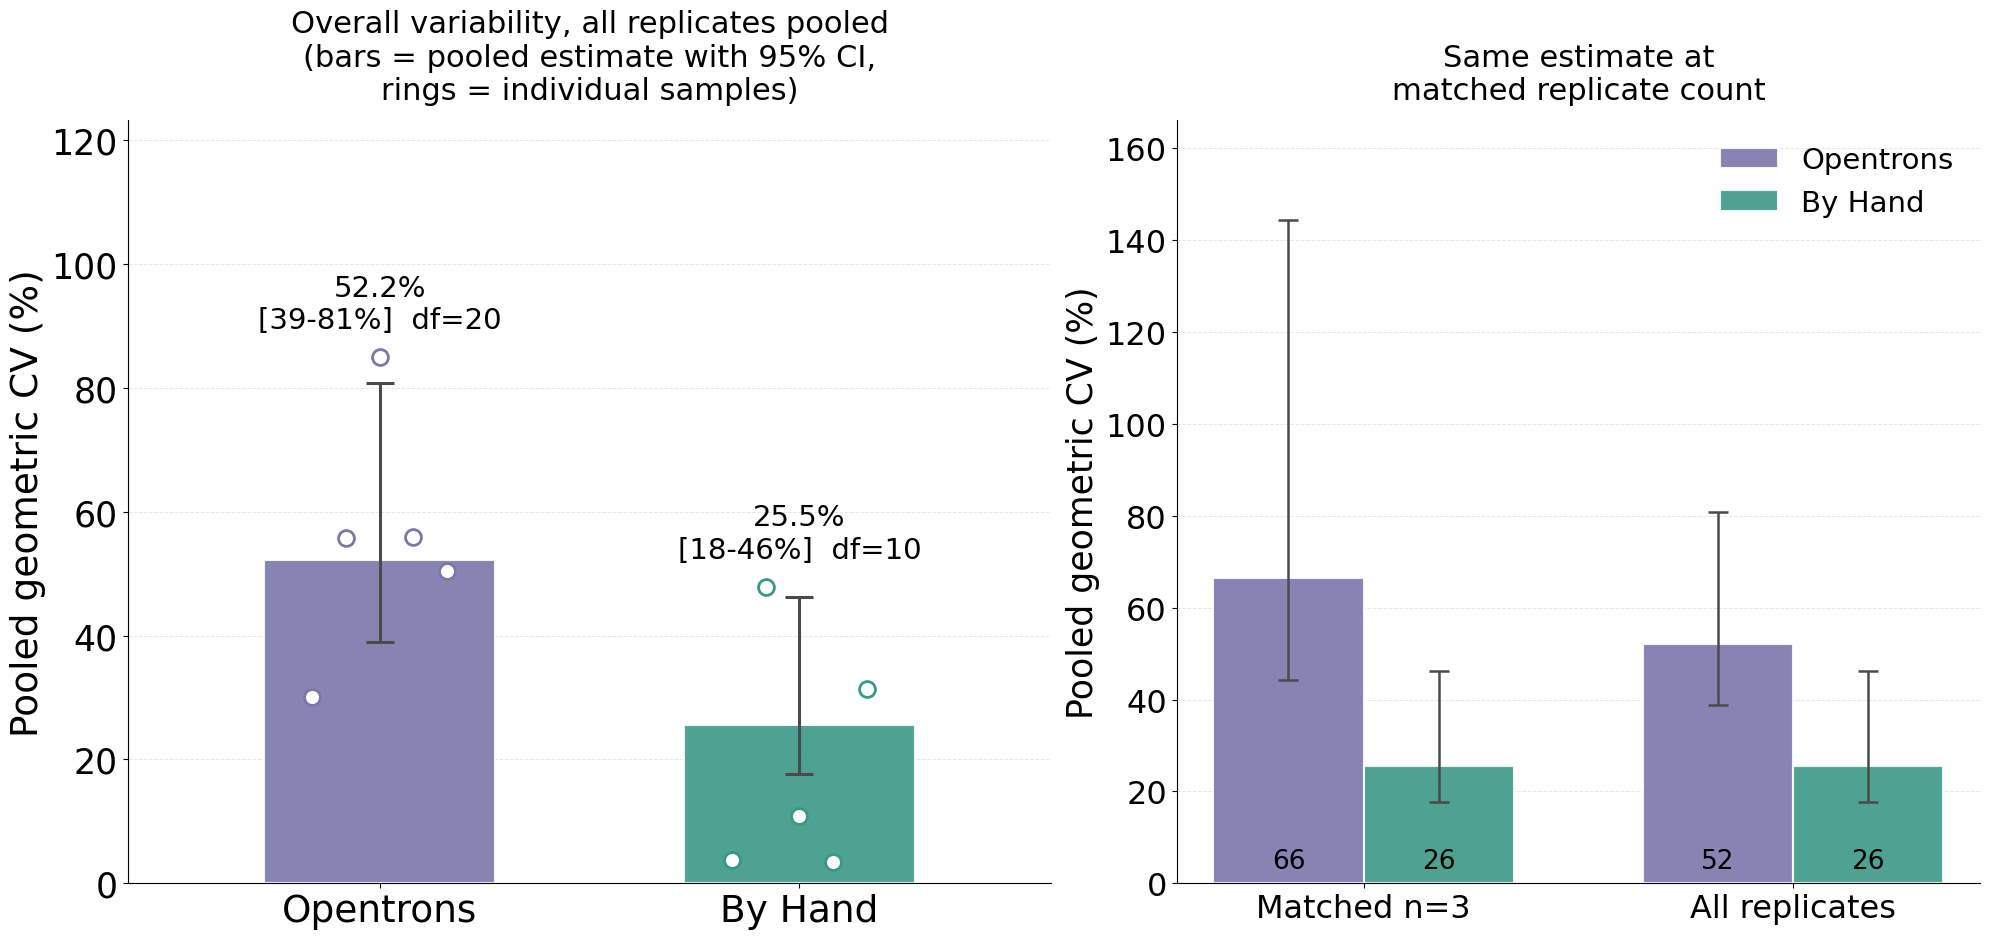

Pooled geometric CV (5 paired samples):

  Matched n=3:
    Opentrons  66.5%  95% CI [44.2, 144.5]  df=10
    By Hand    25.5%  95% CI [17.7, 46.3]  df=10
    Variance ratio F = 5.81 (log scale), p = 0.0102

  All replicates:
    Opentrons  52.2%  95% CI [38.9, 80.8]  df=20
    By Hand    25.5%  95% CI [17.7, 46.3]  df=10
    Variance ratio F = 3.82 (log scale), p = 0.0337



In [33]:
# Overall (pooled) geometric CV per method - the headline variability figure.
# Within-sample log variances are pooled across the paired samples, so every replicate
# contributes and the estimate does not depend on averaging 5 noisy per-sample values.

def pooled_log_sd(method, cap=None):
    """Pooled within-sample SD of log yield, plus its degrees of freedom.

    cap limits each sample to its first `cap` replicates (None = use all).
    """
    ss, dof = 0.0, 0
    for sample in strict_samples:
        values = np.asarray(replicates[(sample, method)], dtype=float)
        logs = np.log(values[:cap] if cap else values)
        ss += ((logs - logs.mean()) ** 2).sum()
        dof += len(logs) - 1
    return np.sqrt(ss / dof), dof


def gcv_from_log_sd(log_sd):
    """Geometric CV (%) from an SD on the natural-log scale."""
    return np.sqrt(np.exp(log_sd ** 2) - 1) * 100


def gcv_ci(log_sd, dof, alpha=0.05):
    """95% CI for the geometric CV, from the chi-square CI on the log-scale variance."""
    var = log_sd ** 2
    lo_var = dof * var / stats.chi2.ppf(1 - alpha / 2, dof)
    hi_var = dof * var / stats.chi2.ppf(alpha / 2, dof)
    return gcv_from_log_sd(np.sqrt(lo_var)), gcv_from_log_sd(np.sqrt(hi_var))


variants = [('Matched n=3', MIN_REPS), ('All replicates', None)]
pooled = {}
for label, cap in variants:
    for method in methods:
        sd, dof = pooled_log_sd(method, cap)
        lo, hi = gcv_ci(sd, dof)
        pooled[(label, method)] = {'log_sd': sd, 'dof': dof, 'GCV': gcv_from_log_sd(sd),
                                   'lo': lo, 'hi': hi}

fig, (ax_main, ax_var) = plt.subplots(1, 2, figsize=(20, 9.5),
                                      gridspec_kw={'width_ratios': [1.15, 1]})

# --- Left: pooled geometric CV, all replicates, with per-sample values overlaid ---
HEADLINE = 'All replicates'
x = np.arange(len(methods))
vals = [pooled[(HEADLINE, m)]['GCV'] for m in methods]
err = np.array([[pooled[(HEADLINE, m)]['GCV'] - pooled[(HEADLINE, m)]['lo'] for m in methods],
                [pooled[(HEADLINE, m)]['hi'] - pooled[(HEADLINE, m)]['GCV'] for m in methods]])

bars = ax_main.bar(x, vals, 0.55, yerr=err, capsize=10,
                   color=[method_color[m] for m in methods], alpha=0.9,
                   edgecolor='white', linewidth=1.5,
                   error_kw={'linewidth': 2.2, 'elinewidth': 2.2, 'capthick': 2.2,
                             'ecolor': '#4A4A4A'})

# Per-sample geometric CVs behind the pooled estimate
sub_all = var_df[var_df['Variant'] == 'All replicates'].set_index(['Sample', 'Method'])
for i, method in enumerate(methods):
    per_sample = [sub_all.loc[(s, method), 'Geometric CV (%)'] for s in strict_samples]
    jitter = np.linspace(-0.16, 0.16, len(per_sample))
    ax_main.scatter(i + jitter, per_sample, s=130, facecolor='white',
                    edgecolor=method_color[method], linewidth=2, zorder=3)

per_sample_max = {m: max(sub_all.loc[(s, m), 'Geometric CV (%)'] for s in strict_samples)
                  for m in methods}
main_top = max(max(pooled[(HEADLINE, m)]['hi'], per_sample_max[m]) for m in methods) * 1.45
for bar, method in zip(bars, methods):
    p = pooled[(HEADLINE, method)]
    label_y = max(p['hi'], per_sample_max[method])
    ax_main.text(bar.get_x() + bar.get_width() / 2, label_y + main_top * 0.03,
                 f"{p['GCV']:.1f}%\n[{p['lo']:.0f}-{p['hi']:.0f}%]  df={p['dof']}",
                 ha='center', va='bottom', fontsize=21)

ax_main.set_ylabel('Pooled geometric CV (%)', fontsize=27)
ax_main.set_xticks(x)
ax_main.set_xticklabels(methods, fontsize=27)
ax_main.tick_params(axis='y', labelsize=25)
ax_main.set_xlim(-0.6, len(methods) - 0.4)
ax_main.set_ylim(0, main_top)
ax_main.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax_main.set_axisbelow(True)
ax_main.set_title('Overall variability, all replicates pooled\n'
                  '(bars = pooled estimate with 95% CI,\nrings = individual samples)',
                  fontsize=22, pad=15)
ax_main.spines['top'].set_visible(False)
ax_main.spines['right'].set_visible(False)

# --- Right: same estimate under matched n=3, to show it is not an artefact of
#     Opentrons having more replicates ---
width = 0.35
for i, method in enumerate(methods):
    vals_v = [pooled[(label, method)]['GCV'] for label, _ in variants]
    err_v = np.array([[pooled[(label, method)]['GCV'] - pooled[(label, method)]['lo']
                       for label, _ in variants],
                      [pooled[(label, method)]['hi'] - pooled[(label, method)]['GCV']
                       for label, _ in variants]])
    xs = np.arange(len(variants)) + (i - 0.5) * width
    b = ax_var.bar(xs, vals_v, width, yerr=err_v, capsize=7, label=method,
                   color=method_color[method], alpha=0.9, edgecolor='white', linewidth=1.5,
                   error_kw={'linewidth': 1.8, 'elinewidth': 1.8, 'capthick': 1.8,
                             'ecolor': '#4A4A4A'})
    for bar, val in zip(b, vals_v):
        ax_var.text(bar.get_x() + bar.get_width() / 2, 2, f'{val:.0f}',
                    ha='center', va='bottom', fontsize=19)

ax_var.set_ylabel('Pooled geometric CV (%)', fontsize=25)
ax_var.set_xticks(np.arange(len(variants)))
ax_var.set_xticklabels([label for label, _ in variants], fontsize=23)
ax_var.tick_params(axis='y', labelsize=23)
ax_var.set_ylim(0, max(p['hi'] for p in pooled.values()) * 1.15)
ax_var.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax_var.set_axisbelow(True)
ax_var.legend(fontsize=21, frameon=False, loc='upper right')
ax_var.set_title('Same estimate at\nmatched replicate count', fontsize=22, pad=15)
ax_var.spines['top'].set_visible(False)
ax_var.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../plots/GeometricCV_Overall.svg', dpi=1000, bbox_inches='tight')
plt.show()

# --- Ratio of variances between methods, with a formal test ---
print(f"Pooled geometric CV ({len(strict_samples)} paired samples):\n")
for label, _ in variants:
    o, h = pooled[(label, 'Opentrons')], pooled[(label, 'By Hand')]
    f_stat = (o['log_sd'] / h['log_sd']) ** 2
    p_val = 2 * min(stats.f.cdf(f_stat, o['dof'], h['dof']),
                    1 - stats.f.cdf(f_stat, o['dof'], h['dof']))
    print(f"  {label}:")
    print(f"    Opentrons {o['GCV']:5.1f}%  95% CI [{o['lo']:.1f}, {o['hi']:.1f}]  df={o['dof']}")
    print(f"    By Hand   {h['GCV']:5.1f}%  95% CI [{h['lo']:.1f}, {h['hi']:.1f}]  df={h['dof']}")
    print(f"    Variance ratio F = {f_stat:.2f} (log scale), p = {p_val:.4f}\n")


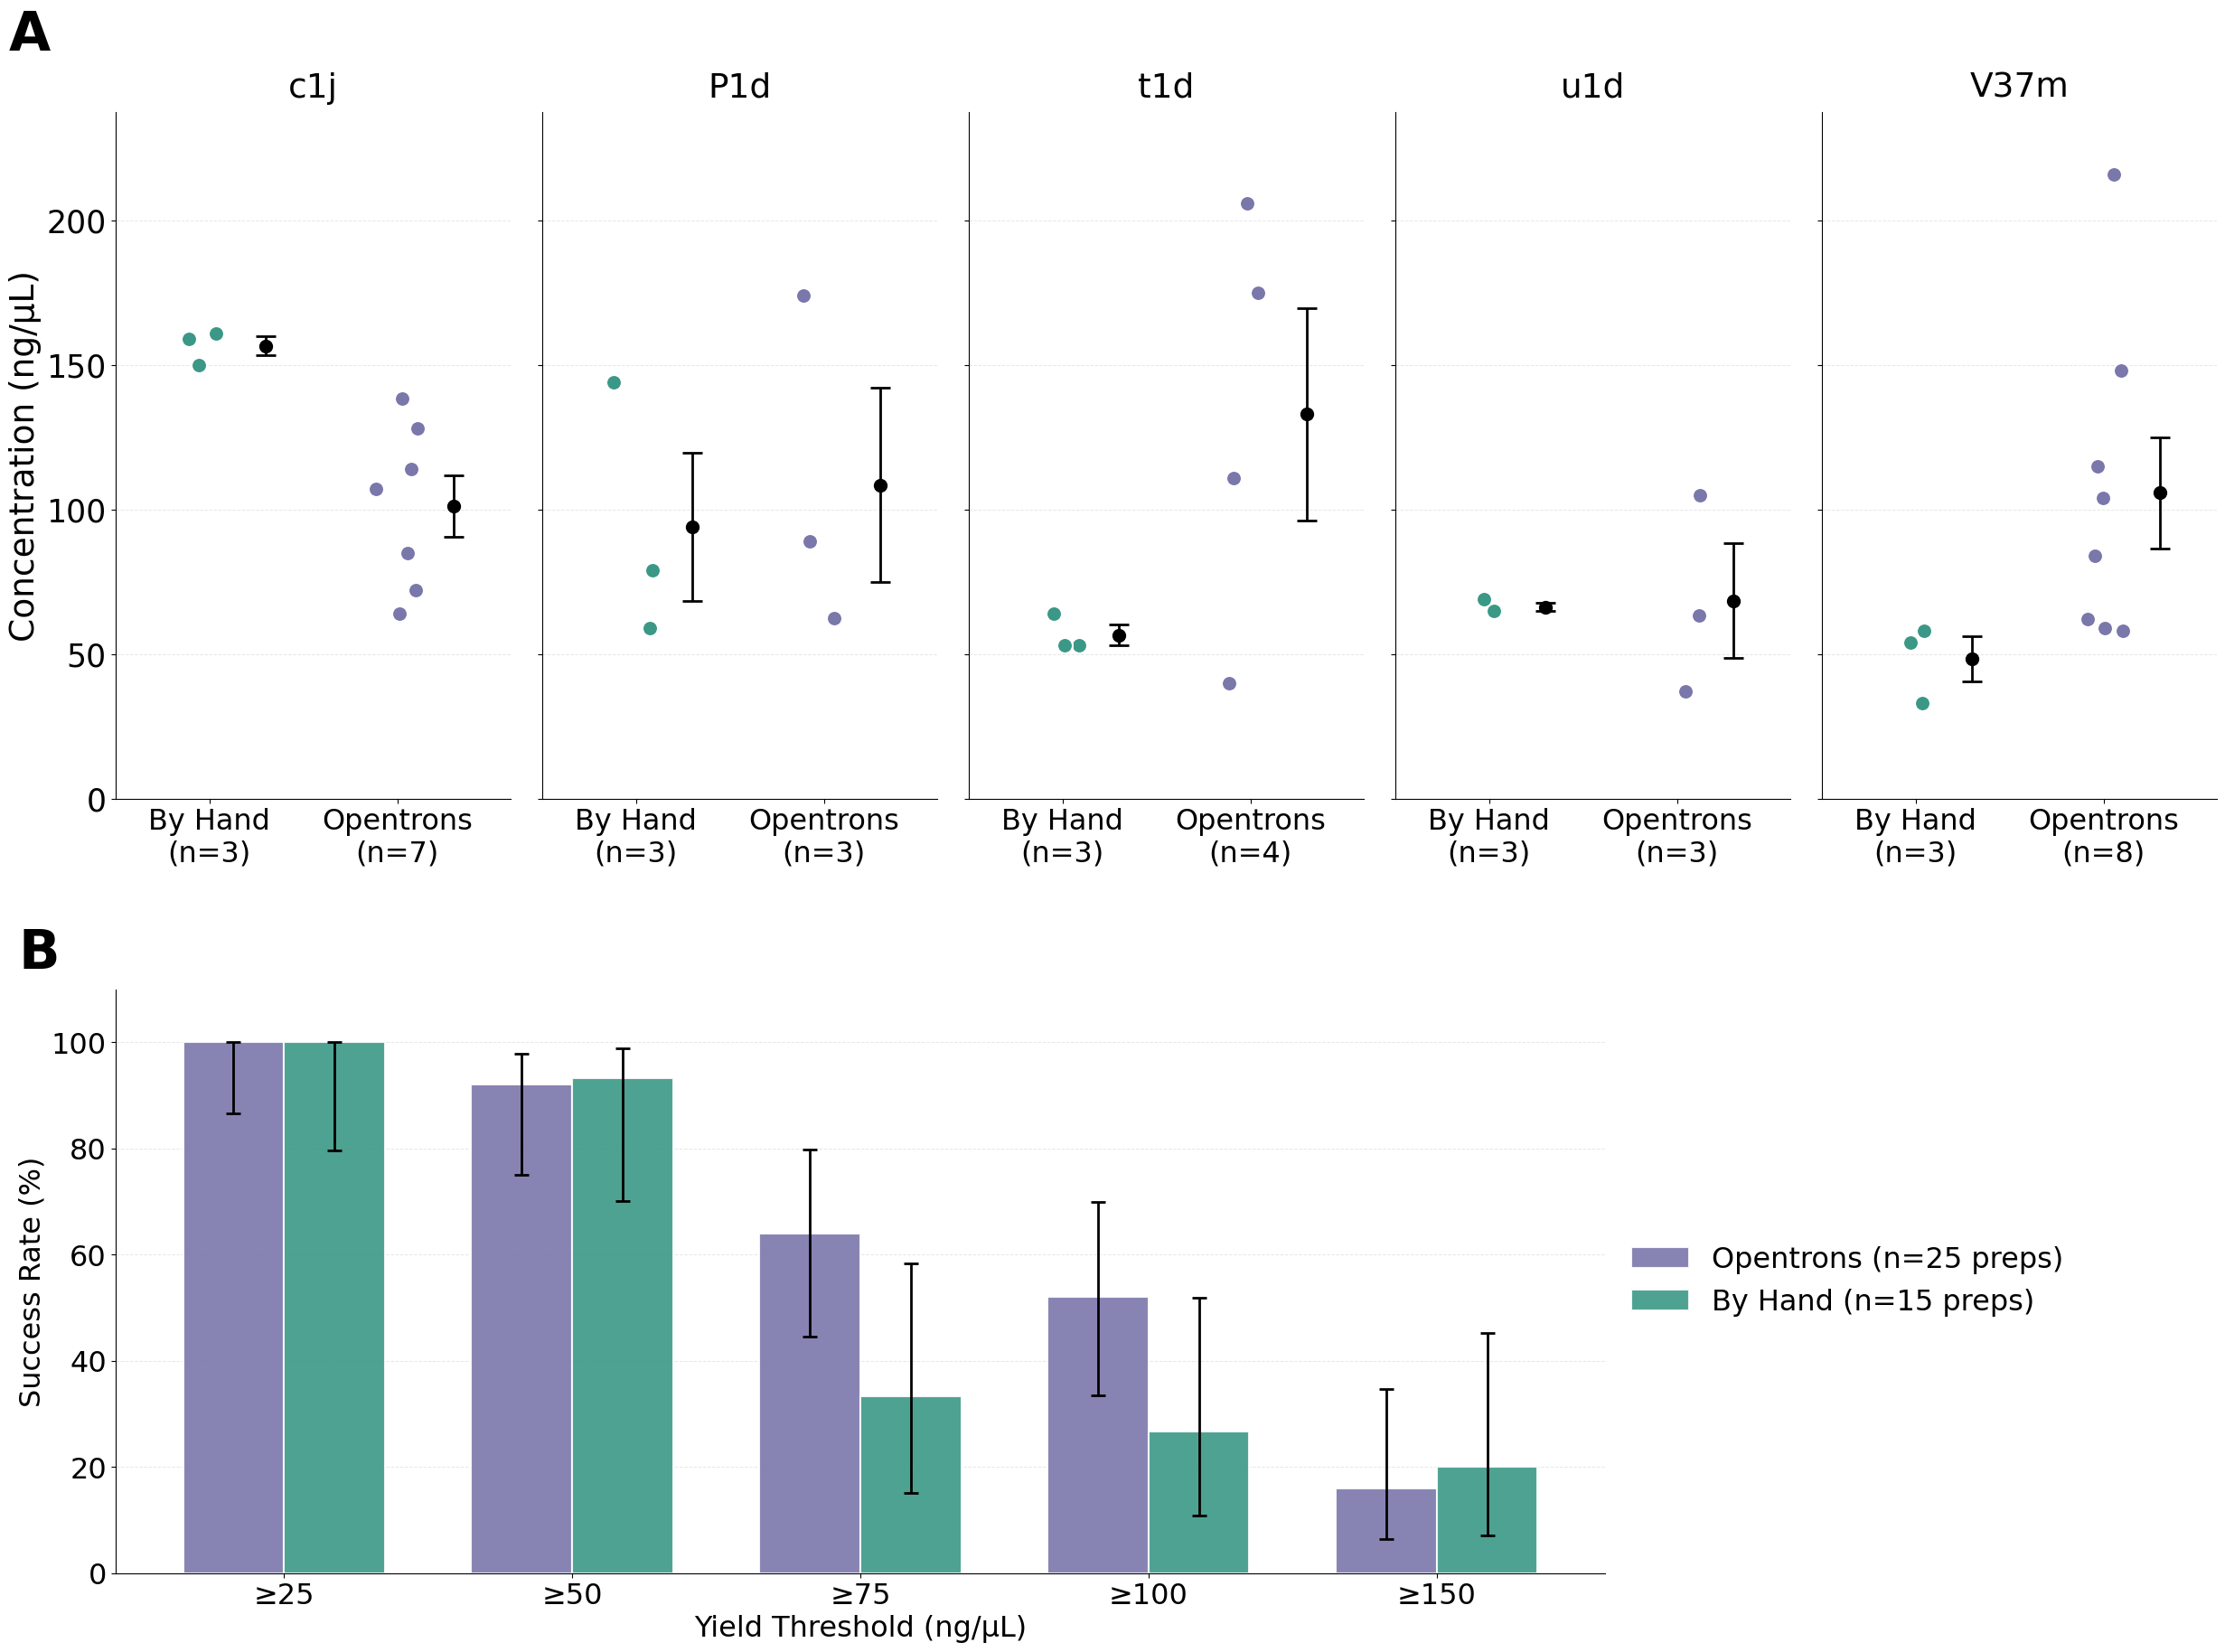

In [34]:
# Combined figure for the plasmids with >= 3 replicates by both methods:
# A per-plasmid yield by method, B success rate by yield threshold.
# Panels are drawn by the same functions as plots/Triplicates_YieldByMethod.svg and plots/SuccessRate.svg.
# Per-plasmid CV is left out: culture round is confounded with method in this routine-use data,
# so the controlled variability comparison is in the C4J figure instead.
fig = plt.figure(figsize=(30, 21))
grid = fig.add_gridspec(2, 1, height_ratios=[1, 0.85], hspace=0.3)

top = grid[0].subgridspec(1, len(df), wspace=0.08)
yield_axes = [fig.add_subplot(top[0, 0])]
yield_axes += [fig.add_subplot(top[0, i], sharey=yield_axes[0]) for i in range(1, len(df))]
for ax in yield_axes[1:]:
    ax.tick_params(labelleft=False)
plot_triplicate_yield(yield_axes)

# Success rate spans most of the width, leaving room on the right for its legend
bottom = grid[1].subgridspec(1, 2, width_ratios=[0.78, 0.22])
success_ax = fig.add_subplot(bottom[0, 0])
plot_success_rate(success_ax)

# Panel letters at the left of each panel's full extent (including axis labels), sharing one
# height per row
renderer = fig.canvas.get_renderer()
panels = [('A', yield_axes, 0), ('B', [success_ax], 1)]
extent = {}
for letter, axes_in_panel, row in panels:
    boxes = [ax.get_tightbbox(renderer).transformed(fig.transFigure.inverted()) for ax in axes_in_panel]
    extent[letter] = (min(b.x0 for b in boxes), max(b.y1 for b in boxes))
row_top = {row: max(extent[l][1] for l, _, r in panels if r == row) for _, _, row in panels}
for letter, _, row in panels:
    fig.text(extent[letter][0], row_top[row] + 0.005, letter, fontsize=43, fontweight='bold', ha='left', va='bottom')

plt.savefig('../plots/Triplicates_Combined.svg', dpi=1000, bbox_inches='tight')
# Raster copy for submission systems and slides
plt.savefig('../plots/Triplicates_Combined.png', dpi=600, bbox_inches='tight', facecolor='white')
plt.show()